In [2]:
2+5

7

In [16]:
from pathlib import Path
from datetime import datetime
import csv
import hashlib
import re

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from scipy.ndimage import map_coordinates
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from scipy.constants import c as LIGHT_SPEED, k as BOLTZMANN
from astropy.io import fits


# 解析する年のフォルダ
FITS_ROOT = Path("/Users/reiya/Desktop/imaging/results_fov3000/2026")
FITS_FILES = sorted(FITS_ROOT.rglob("*_mimg.fits"))

# "peak"：選んだピークの横断位置を直接採用
# "gaussian"：従来の横断ガウシアンフィット
POSITION_METHOD = "peak"
#POSITION_METHOD = "gaussian"


if POSITION_METHOD not in {"peak", "gaussian"}:
    raise ValueError('POSITION_METHODは "peak" または "gaussian" を指定してください')

OUT_DIR = FITS_ROOT / ("Jet1AB_PA145_peak" if POSITION_METHOD == "peak" else "Jet1AB_PA145")

PA_DEG = 145.0
DISTANCES_MAS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2]

# FITSヘッダーから画素スケールを読めない場合に使用
FALLBACK_FOV_MAS = 3.0
FALLBACK_X_EAST_SIGN = -1
FALLBACK_Y_NORTH_SIGN = 1

CORE_FIT_HALF_PIX = 3
CORE_XY_BY_EPOCH = {}

TRANSVERSE_HALF_WIDTH_MAS = 0.5
SAMPLE_STEP_MAS = 0.01
SLICE_THICKNESS_MAS = 0.0

# 灰色の候補探索範囲
FIT_WINDOW_MAS = (-0.30, 0.20)
FIT_WINDOW_BY_DISTANCE = {0.4: (-0.30, 0.25)}

MAX_PEAKS = 3
PEAK_PROMINENCE_FRACTION = 0.08
PEAK_DISTANCE_PIX = 2.0

DISPLAY_TB = True
OBS_FREQUENCY_GHZ = 43.0

# 従来のガウシアン方式で使う品質判定
NOISE_BY_EPOCH = {}
MIN_SNR = 5.0
REVIEW_NRMS_LIMIT = 0.12
COMPONENT_REVIEW_OVERRIDES = {}
SHOW_FORMAL_FIT_ERRORS = False

SHOW_FIGURES = True
COLOURS = {"Jet1A": "tab:blue", "Jet1B": "tab:red"}
_PREVIEW = {}

In [18]:
def angular_matrix(header, shape):
    """画素の位置差を東・北方向の位置差 [mas] に変換する。"""
    ny, nx = shape

    if any(key in header for key in ("CD1_1", "CD1_2", "CD2_1", "CD2_2")):
        matrix = np.array([
            [header.get("CD1_1", 0), header.get("CD1_2", 0)],
            [header.get("CD2_1", 0), header.get("CD2_2", 0)],
        ], dtype=float)

    elif "CDELT1" in header and "CDELT2" in header:
        pc = np.array([
            [header.get("PC1_1", 1), header.get("PC1_2", 0)],
            [header.get("PC2_1", 0), header.get("PC2_2", 1)],
        ], dtype=float)
        matrix = np.diag([header["CDELT1"], header["CDELT2"]]) @ pc

    else:
        if FALLBACK_FOV_MAS is None:
            raise ValueError("FALLBACK_FOV_MASを指定してください")

        return np.diag([
            FALLBACK_X_EAST_SIGN * FALLBACK_FOV_MAS / nx,
            FALLBACK_Y_NORTH_SIGN * FALLBACK_FOV_MAS / ny,
        ])

    units = {
        "deg": 3600000.0,
        "degree": 3600000.0,
        "mas": 1.0,
        "arcsec": 1000.0,
        "rad": 180 / np.pi * 3600000.0,
    }

    for i in range(2):
        unit = str(header.get(f"CUNIT{i + 1}", "deg")).strip().lower()

        if unit not in units:
            raise ValueError(f"未対応の角度単位：{unit}")

        matrix[i] *= units[unit]

    if not np.all(np.isfinite(matrix)) or abs(np.linalg.det(matrix)) < 1e-20:
        raise ValueError("角度スケールが不正です")

    return matrix


def core_gaussian(coords, amplitude, x0, y0, sx, sy, angle, background):
    """コア中心を求めるための回転した2次元ガウス。"""
    x, y = coords
    dx = x - x0
    dy = y - y0

    q = dx * np.cos(angle) + dy * np.sin(angle)
    r = -dx * np.sin(angle) + dy * np.cos(angle)

    return background + amplitude * np.exp(
        -0.5 * ((q / sx) ** 2 + (r / sy) ** 2)
    )


def find_core(data, epoch):
    """最大輝度画素の近くからコア中心を求める。"""
    if epoch in CORE_XY_BY_EPOCH:
        core = np.asarray(CORE_XY_BY_EPOCH[epoch], dtype=float)

        if (
            core.shape != (2,)
            or not np.all(np.isfinite(core))
            or not 0 <= core[0] < data.shape[1]
            or not 0 <= core[1] < data.shape[0]
        ):
            raise ValueError("手動コア位置が不正です")

        return core, "manual"

    good = np.isfinite(data)

    if not good.any():
        raise ValueError("有限な画素がありません")

    peak_y, peak_x = np.unravel_index(
        np.argmax(np.where(good, data, -np.inf)),
        data.shape,
    )

    yy, xx = np.indices(data.shape)
    half_size = CORE_FIT_HALF_PIX

    mask = (
        good
        & (abs(xx - peak_x) <= half_size)
        & (abs(yy - peak_y) <= half_size)
    )

    values = data[mask]
    if len(values) < 12 or np.ptp(values) <= 0:
        raise ValueError("コアfit用データ不足")

    normalized = (values - values.min()) / np.ptp(values)

    parameters, _ = curve_fit(
        core_gaussian,
        (xx[mask], yy[mask]),
        normalized,
        p0=[1.0, peak_x, peak_y, 1.0, 1.0, 0.0, 0.0],
        bounds=(
            [0.0, peak_x - 1.5, peak_y - 1.5, 0.3, 0.3, -np.pi, -1.0],
            [
                3.0, peak_x + 1.5, peak_y + 1.5,
                2 * half_size, 2 * half_size, np.pi, 1.0,
            ],
        ),
        maxfev=30000,
    )

    if abs(parameters[1] - peak_x) > 1.45 or abs(parameters[2] - peak_y) > 1.45:
        raise ValueError("コアfitが境界です。CORE_XY_BY_EPOCHで指定してください")

    return np.array(parameters[1:3]), "gaussian2d"


def input_files():
    """FITSの存在と観測日の重複を確認する。"""
    pairs = []

    for file in FITS_FILES:
        path = Path(file).expanduser()

        if not path.is_file():
            raise FileNotFoundError(f"見つかりません：{path}")

        match = re.search(r"\d{4}-\d{2}-\d{2}", path.name)
        if match is None:
            raise ValueError(f"ファイル名に観測日がありません：{path.name}")

        pairs.append((match.group(), path))

    if not pairs or len({epoch for epoch, _ in pairs}) != len(pairs):
        raise ValueError("FITSは観測日ごとに1枚ずつ指定してください")

    return sorted(pairs)


def load_epoch(epoch, path):
    """FITSを読み込み、コア位置と表示単位を決める。"""
    data, header = fits.getdata(path, header=True)
    data = np.asarray(data, dtype=float).squeeze()

    if data.ndim != 2:
        raise ValueError("2次元のI画像を指定してください")

    matrix = angular_matrix(header, data.shape)
    core, method = find_core(data, epoch)
    unit = str(header.get("BUNIT", "")).strip()
    factor = 1.0

    if DISPLAY_TB:
        name = unit.lower().replace(" ", "")

        if name in ("jy/pixel", "jy/pix"):
            omega = (
                abs(np.linalg.det(matrix))
                * (np.pi / (180 * 3600000)) ** 2
            )
            frequency = OBS_FREQUENCY_GHZ * 1e9
            factor = (
                1e-26 * LIGHT_SPEED ** 2
                / (2 * BOLTZMANN * frequency ** 2 * omega)
            )
            data = data * factor

        elif name not in ("k", "kelvin"):
            raise ValueError(f"Tb変換未対応のBUNIT：{unit}")

        unit = "Brightness temperature (K)"

    noise = NOISE_BY_EPOCH.get(epoch)

    if noise is not None:
        noise *= factor

        if not np.isfinite(noise) or noise <= 0:
            raise ValueError("ノイズは正の有限値で指定してください")

    settings = (
        PA_DEG, DISTANCES_MAS, TRANSVERSE_HALF_WIDTH_MAS,
        SAMPLE_STEP_MAS, SLICE_THICKNESS_MAS, FIT_WINDOW_MAS,
        FIT_WINDOW_BY_DISTANCE, MAX_PEAKS, PEAK_PROMINENCE_FRACTION,
        PEAK_DISTANCE_PIX, core.tolist(), matrix.tolist(), unit,
    )

    signature = hashlib.sha256(
        data.tobytes() + repr(settings).encode()
    ).hexdigest()

    return dict(
        epoch=epoch,
        data=data,
        matrix=matrix,
        core=core,
        method=method,
        unit=unit,
        noise=noise,
        signature=signature,
        pixel=np.linalg.svd(matrix, compute_uv=False).min(),
    )


def directions():
    """東・北座標での軸方向と横断方向を返す。"""
    pa = np.deg2rad(PA_DEG)
    along = np.array([np.sin(pa), np.cos(pa)])
    across = np.array([np.cos(pa), -np.sin(pa)])
    return along, across


def slice_grid():
    return np.arange(
        -TRANSVERSE_HALF_WIDTH_MAS,
        TRANSVERSE_HALF_WIDTH_MAS + SAMPLE_STEP_MAS / 2,
        SAMPLE_STEP_MAS,
    )


def extract_profile(item, distance, u):
    """コア基準の横断プロファイルを補間して取得する。"""
    along, across = directions()
    width = SLICE_THICKNESS_MAS

    if width > 0:
        offsets = np.linspace(
            -width / 2,
            width / 2,
            max(3, int(np.ceil(width / item["pixel"])) + 1),
        )
    else:
        offsets = [0.0]

    values = []

    for offset in offsets:
        en = along[:, None] * (distance + offset) + across[:, None] * u
        xy = item["core"][:, None] + np.linalg.solve(item["matrix"], en)

        values.append(map_coordinates(
            item["data"],
            [xy[1], xy[0]],
            order=1,
            mode="constant",
            cval=np.nan,
            prefilter=False,
        ))

    values = np.asarray(values)
    valid = np.isfinite(values).all(axis=0)
    result = np.full(u.shape, np.nan)
    result[valid] = values[:, valid].mean(axis=0)
    return result


def panels():
    nrows = (len(DISTANCES_MAS) + 1) // 2
    return plt.subplots(
        nrows, 2,
        figsize=(11, 3.2 * nrows),
        squeeze=False,
        layout="constrained",
    )


def save_figure(fig, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=170, bbox_inches="tight")

    if SHOW_FIGURES:
        plt.show()

    plt.close(fig)


def save_csv(path, rows, fields):
    path.parent.mkdir(parents=True, exist_ok=True)

    with path.open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

In [20]:
def peak_candidates(u, intensity, window, pixel):
    mask = np.isfinite(intensity) & (u >= window[0]) & (u <= window[1])
    x = u[mask]
    y = intensity[mask]

    if len(x) < 5 or np.ptp(y) <= 0:
        return []

    peaks, info = find_peaks(
        y,
        prominence=PEAK_PROMINENCE_FRACTION * np.ptp(y),
        distance=max(
            1,
            int(np.ceil(PEAK_DISTANCE_PIX * pixel / SAMPLE_STEP_MAS)),
        ),
    )

    chosen = peaks[np.argsort(info["prominences"])[-MAX_PEAKS:]]
    chosen = sorted(chosen, key=lambda p: x[p])

    return [
        dict(id=i + 1, u=float(x[p]), intensity=float(y[p]))
        for i, p in enumerate(chosen)
    ]


def preview_peak_candidates():
    """番号入力の前に候補図だけを見たい場合に使用する。"""
    _PREVIEW.clear()
    out = OUT_DIR.expanduser() / "00_peak_candidates"
    records = []
    u = slice_grid()

    for epoch, path in input_files():
        item = load_epoch(epoch, path)
        _PREVIEW[epoch] = item["signature"]
        fig, axes = panels()

        for j, distance in enumerate(DISTANCES_MAS):
            intensity = extract_profile(item, distance, u)
            window = FIT_WINDOW_BY_DISTANCE.get(distance, FIT_WINDOW_MAS)
            peaks = peak_candidates(u, intensity, window, item["pixel"])
            ax = axes.flat[j]

            ax.plot(u, intensity, color="black")
            ax.axvspan(*window, color="grey", alpha=0.12)

            for peak in peaks:
                ax.plot(peak["u"], peak["intensity"], "o", color="darkorange")
                ax.annotate(
                    str(peak["id"]),
                    (peak["u"], peak["intensity"]),
                    xytext=(0, 8),
                    textcoords="offset points",
                    ha="center",
                    color="darkorange",
                )
                records.append(dict(
                    epoch=epoch,
                    distance_mas=distance,
                    peak_id=peak["id"],
                    transverse_mas=peak["u"],
                    intensity=peak["intensity"],
                    unit=item["unit"],
                ))

            ax.margins(y=0.2)
            ax.set(
                title=f"{epoch}: d={distance:g} mas",
                xlabel="Transverse offset (mas)",
                ylabel=item["unit"],
            )
            ax.grid(alpha=0.2)

            print(
                f"{epoch}, {distance:g} mas:",
                [(peak["id"], round(peak["u"], 3)) for peak in peaks],
            )

        for ax in list(axes.flat)[len(DISTANCES_MAS):]:
            ax.set_visible(False)

        save_figure(fig, out / f"{epoch}.png")

    save_csv(
        out / "peak_candidates.csv",
        records,
        ["epoch", "distance_mas", "peak_id", "transverse_mas", "intensity", "unit"],
    )

In [22]:
def fit_selected(item, distance, u, intensity, selection):
    """POSITION_METHOD='gaussian' のときに使う従来の処理。"""
    selection = {
        label: peak_id
        for label, peak_id in selection.items()
        if peak_id is not None
    }

    if not selection or not set(selection) <= {"Jet1A", "Jet1B"}:
        raise ValueError("Select Jet1A / Jet1B peak IDs")

    if len(set(selection.values())) != len(selection):
        raise ValueError("Duplicate peak IDs")

    window = FIT_WINDOW_BY_DISTANCE.get(distance, FIT_WINDOW_MAS)
    peaks = peak_candidates(u, intensity, window, item["pixel"])

    if not set(selection.values()) <= {peak["id"] for peak in peaks}:
        raise ValueError("Selected peak ID not found")

    mask = np.isfinite(intensity) & (u >= window[0]) & (u <= window[1])
    x = u[mask]
    raw = intensity[mask]
    n = len(peaks)

    if len(x) <= 3 * n + 1 or np.ptp(raw) <= 0:
        raise ValueError("Not enough profile data")

    base = float(raw.min())
    scale = float(np.ptp(raw))
    normalized = (raw - base) / scale
    centers = np.array([peak["u"] for peak in peaks])
    edges = np.r_[window[0], (centers[:-1] + centers[1:]) / 2, window[1]]

    sigma_min = max(item["pixel"] / 2, 1e-4)
    sigma_max = window[1] - window[0]
    initial, lower, upper = [], [], []

    for i, peak in enumerate(peaks):
        initial += [
            max((peak["intensity"] - base) / scale, 0.05),
            peak["u"],
            min(max(0.04, sigma_min * 1.2), sigma_max * 0.4),
        ]
        lower += [0.0, edges[i], sigma_min]
        upper += [5.0, edges[i + 1], sigma_max]

    initial.append(0.0)
    lower.append(-1.0)
    upper.append(1.0)

    def model(q, *parameters):
        result = np.full_like(q, parameters[-1], dtype=float)

        for i in range(n):
            amplitude, center, sigma = parameters[3 * i:3 * i + 3]
            result += amplitude * np.exp(-0.5 * ((q - center) / sigma) ** 2)

        return result

    parameters, covariance = curve_fit(
        model, x, normalized,
        p0=initial,
        bounds=(lower, upper),
        maxfev=50000,
    )

    total = model(u, *parameters) * scale + base
    background = parameters[-1] * scale + base
    nrms = float(np.sqrt(np.mean((normalized - model(x, *parameters)) ** 2)))
    labels = {peak_id: label for label, peak_id in selection.items()}

    rows = []
    curves = {}

    for i, peak in enumerate(peaks):
        amplitude, center, sigma = parameters[3 * i:3 * i + 3]
        label = labels.get(peak["id"], f"Other{peak['id']}")
        variance = covariance[3 * i + 1, 3 * i + 1]
        flags = []

        if nrms > REVIEW_NRMS_LIMIT:
            flags.append("poor_fit")
        if not np.isfinite(variance):
            flags.append("uncertain_center")
        if min(center - edges[i], edges[i + 1] - center) < SAMPLE_STEP_MAS:
            flags.append("center_at_bound")
        if sigma <= sigma_min * 1.02 or sigma >= sigma_max * 0.98:
            flags.append("width_at_bound")
        if amplitude < 0.08:
            flags.append("weak_component")
        if background < -0.02 * scale:
            flags.append("negative_background")
        if item["noise"] is not None and amplitude * scale / item["noise"] < MIN_SNR:
            flags.append("low_snr")

        if n > 1:
            nearest_separation = min(
                abs(center - parameters[3 * j + 1])
                for j in range(n)
                if j != i
            )

            if nearest_separation < PEAK_DISTANCE_PIX * item["pixel"]:
                flags.append("close_centers")

        requested = label in selection
        accepted = requested and not flags
        key = (item["epoch"], distance, label)

        if key in COMPONENT_REVIEW_OVERRIDES:
            accepted = requested and bool(COMPONENT_REVIEW_OVERRIDES[key])

        curves[label] = (
            amplitude * scale * np.exp(-0.5 * ((u - center) / sigma) ** 2)
        )

        rows.append(dict(
            epoch=item["epoch"],
            distance_mas=distance,
            peak_id=peak["id"],
            component=label,
            transverse_mas=float(center),
            fit_error_approx_mas=float(np.sqrt(max(variance, 0))),
            observed_fwhm_mas=float(sigma * np.sqrt(8 * np.log(2))),
            amplitude=float(amplitude * scale),
            intensity_unit=item["unit"],
            requested=requested,
            accepted=accepted,
            status="review:" + ";".join(flags) if flags else "ok",
            fit_nrms=nrms,
        ))

    return rows, total, background, curves


def run_analysis():
    pairs = input_files()
    items = [load_epoch(epoch, path) for epoch, path in pairs]

    for item in items:
        if _PREVIEW.get(item["epoch"]) != item["signature"]:
            raise ValueError("最新の候補図を表示して、番号を選び直してください")

    out = OUT_DIR.expanduser()
    u = slice_grid()
    along, across = directions()
    rows, core_rows, profile_rows, statuses = [], [], [], []

    for item in items:
        epoch = item["epoch"]
        core_rows.append(dict(
            epoch=epoch,
            core_x_pix=item["core"][0],
            core_y_pix=item["core"][1],
            method=item["method"],
        ))

        print(f"{epoch}: core=({item['core'][0]:.3f}, {item['core'][1]:.3f})")

        fig, axes = panels()
        imfig, imax = plt.subplots(figsize=(6, 6), layout="constrained")

        yy, xx = np.indices(item["data"].shape)
        pixel_offsets = np.stack([
            xx - item["core"][0],
            yy - item["core"][1],
        ])
        en = (
            item["matrix"] @ pixel_offsets.reshape(2, -1)
        ).reshape(2, *item["data"].shape)

        positive = item["data"][
            np.isfinite(item["data"]) & (item["data"] > 0)
        ]
        if not len(positive):
            raise ValueError("正の強度がありません")

        vmax = positive.max()
        vmin = min(max(np.percentile(positive, 10), vmax * 1e-4), vmax * 0.99)
        image = imax.pcolormesh(
            *en, item["data"],
            shading="nearest",
            cmap="inferno",
            norm=LogNorm(vmin, vmax),
        )

        imax.plot(0, 0, "c+", ms=13)
        end = along * (max(DISTANCES_MAS) + 0.1)
        imax.plot(
            [0, end[0]], [0, end[1]],
            "c--", lw=1, label=f"PA={PA_DEG:g} deg",
        )

        for j, distance in enumerate(DISTANCES_MAS):
            ax = axes.flat[j]
            intensity = extract_profile(item, distance, u)
            window = FIT_WINDOW_BY_DISTANCE.get(distance, FIT_WINDOW_MAS)
            mask = (u >= window[0]) & (u <= window[1])

            ax.plot(u, intensity, color="black", label="Slice")
            ax.axvspan(*window, color="grey", alpha=0.12)

            ends = (
                along[:, None] * distance
                + across[:, None] * np.array([
                    -TRANSVERSE_HALF_WIDTH_MAS,
                    TRANSVERSE_HALF_WIDTH_MAS,
                ])
            )
            imax.plot(*ends, lw=0.7, color="white", alpha=0.5)

            total = np.full(u.shape, np.nan)
            background = np.nan
            curves = {}
            selection = {
                label: peak_id
                for label, peak_id in PEAK_SELECTION.get((epoch, distance), {}).items()
                if peak_id is not None
            }
            status = "not_selected"

            if selection and POSITION_METHOD == "peak":
                candidates = {
                    peak["id"]: peak
                    for peak in peak_candidates(u, intensity, window, item["pixel"])
                }
                missing = set(selection.values()) - candidates.keys()

                if missing:
                    raise ValueError(
                        f"{epoch}, {distance:g} mas: 候補 {sorted(missing)} がありません。"
                        "候補図を再表示して番号を選び直してください。"
                    )

                for label, peak_id in selection.items():
                    peak = candidates[peak_id]
                    offset = peak["u"]
                    brightness = peak["intensity"]
                    key = (epoch, distance, label)
                    accepted = bool(COMPONENT_REVIEW_OVERRIDES.get(key, True))

                    rows.append(dict(
                        epoch=epoch,
                        distance_mas=distance,
                        peak_id=peak_id,
                        component=label,
                        transverse_mas=offset,
                        peak_intensity=brightness,
                        position_method="sampled_peak",
                        intensity_unit=item["unit"],
                        requested=True,
                        accepted=accepted,
                        status="peak_selected" if accepted else "manual_reject",
                    ))

                    colour = COLOURS[label]
                    marker = "o" if accepted else "x"
                    ax.plot(
                        offset, brightness, marker,
                        color=colour, label=f"{label} peak",
                    )
                    ax.axvline(offset, color=colour, ls=":")

                    point = along * distance + across * offset
                    imax.plot(*point, marker, color=colour, ms=5)

                status = "peak_selected"

            elif selection:
                try:
                    fitted, total, background, curves = fit_selected(
                        item, distance, u, intensity, selection,
                    )

                    for row in fitted:
                        row["position_method"] = "gaussian"

                    rows.extend(fitted)
                    status = "fitted"
                    ax.plot(u[mask], total[mask], "--", color="purple", label="Total fit")

                    for rank, row in enumerate(fitted):
                        label = row["component"]
                        colour = COLOURS.get(label, "grey")

                        ax.plot(
                            u[mask], (curves[label] + background)[mask],
                            color=colour, label=label + " + background",
                        )
                        ax.axvline(row["transverse_mas"], color=colour, ls=":")
                        ax.text(
                            0.02, 0.98 - rank * 0.09,
                            label + ": " + row["status"],
                            transform=ax.transAxes,
                            va="top", fontsize=7, color=colour,
                        )

                        point = along * distance + across * row["transverse_mas"]
                        marker = "o" if row["accepted"] else "x"
                        imax.plot(*point, marker, color=colour, ms=5)

                except (ValueError, RuntimeError) as exc:
                    status = str(exc)
                    print(f"  {distance:g} mas: {status}")

            if status not in {"fitted", "peak_selected"}:
                ax.text(0.02, 0.95, status, transform=ax.transAxes, va="top", fontsize=8)

            statuses.append(dict(epoch=epoch, distance_mas=distance, status=status))

            empty_curve = np.full(u.shape, np.nan)
            curve_a = curves.get("Jet1A", empty_curve)
            curve_b = curves.get("Jet1B", empty_curve)

            for k, offset in enumerate(u):
                profile_rows.append(dict(
                    epoch=epoch,
                    distance_mas=distance,
                    transverse_mas=offset,
                    intensity=intensity[k],
                    total_fit=total[k],
                    background=background,
                    Jet1A=curve_a[k],
                    Jet1B=curve_b[k],
                ))

            ax.set(
                title=f"{epoch}: d={distance:g} mas",
                xlabel="Transverse offset (mas)",
                ylabel=item["unit"],
            )
            ax.legend(fontsize=7)
            ax.grid(alpha=0.2)

        for ax in list(axes.flat)[len(DISTANCES_MAS):]:
            ax.set_visible(False)

        imax.set(
            title=epoch,
            xlabel="Relative RA (mas)",
            ylabel="Relative Dec (mas)",
            aspect="equal",
        )
        imax.invert_xaxis()
        imax.legend(fontsize=8)
        imfig.colorbar(image, ax=imax, label=item["unit"], shrink=0.8)
        save_figure(imfig, out / "01_core_and_slices" / f"{epoch}.png")
        save_figure(fig, out / "02_profiles" / f"{epoch}.png")

    fields = [
        "epoch", "distance_mas", "peak_id", "component", "transverse_mas",
        "fit_error_approx_mas", "observed_fwhm_mas", "amplitude",
        "intensity_unit", "requested", "accepted", "status", "fit_nrms",
        "position_method", "peak_intensity",
    ]

    save_csv(out / "all_components.csv", rows, fields)
    save_csv(
        out / "core_positions.csv", core_rows,
        ["epoch", "core_x_pix", "core_y_pix", "method"],
    )
    save_csv(out / "slice_status.csv", statuses, ["epoch", "distance_mas", "status"])
    save_csv(
        out / "profiles.csv", profile_rows,
        [
            "epoch", "distance_mas", "transverse_mas", "intensity",
            "total_fit", "background", "Jet1A", "Jet1B",
        ],
    )

    finite_positions = [
        abs(row["transverse_mas"])
        for row in rows
        if row["requested"] and np.isfinite(row["transverse_mas"])
    ]
    ylim = max(0.05, max(finite_positions, default=0.04) * 1.25)
    times = [datetime.fromisoformat(epoch) for epoch, _ in pairs]

    for label in ("Jet1A", "Jet1B"):
        selected_rows = [row for row in rows if row["component"] == label]
        save_csv(out / f"{label}_measurements.csv", selected_rows, fields)
        fig, axes = panels()

        for j, distance in enumerate(DISTANCES_MAS):
            ax = axes.flat[j]
            by_date = {
                row["epoch"]: row
                for row in selected_rows
                if row["distance_mas"] == distance
            }
            values, errors = [], []

            for epoch, _ in pairs:
                row = by_date.get(epoch)
                values.append(
                    row["transverse_mas"] if row and row["accepted"] else np.nan
                )
                errors.append(
                    row.get("fit_error_approx_mas", np.nan)
                    if row and row["accepted"] else np.nan
                )

            if SHOW_FORMAL_FIT_ERRORS and POSITION_METHOD == "gaussian":
                ax.errorbar(
                    times, values, yerr=errors,
                    fmt="o-", color=COLOURS[label], capsize=3,
                )
            else:
                ax.plot(times, values, "o-", color=COLOURS[label], ms=4)

            review = [row for row in by_date.values() if not row["accepted"]]
            ax.plot(
                [datetime.fromisoformat(row["epoch"]) for row in review],
                [row["transverse_mas"] for row in review],
                "x", color="grey",
            )
            ax.axhline(0, color="grey", ls="--", lw=0.8)
            ax.set(
                title=f"{label}: d={distance:g} mas",
                xlabel="Observation date",
                ylabel="Transverse position (mas)",
                ylim=(-ylim, ylim),
            )
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
            ax.tick_params(axis="x", labelrotation=30)
            ax.grid(alpha=0.2)

        for ax in list(axes.flat)[len(DISTANCES_MAS):]:
            ax.set_visible(False)

        save_figure(fig, out / "03_time_series" / f"{label}.png")

    print(f"保存先：{out}")
    return rows, core_rows

In [24]:
from IPython.display import Image, display


def show_slice_map(item):
    """コア基準の画像にスライス線を重ねる。"""
    data = item["data"]
    ny, nx = data.shape

    yy, xx = np.meshgrid(
        np.arange(ny + 1) - 0.5,
        np.arange(nx + 1) - 0.5,
        indexing="ij",
    )
    pixel_offsets = np.stack([
        xx - item["core"][0],
        yy - item["core"][1],
    ])
    en = (
        item["matrix"] @ pixel_offsets.reshape(2, -1)
    ).reshape(2, ny + 1, nx + 1)

    positive = data[np.isfinite(data) & (data > 0)]
    if positive.size == 0:
        raise ValueError("画像に正の強度がありません")

    vmax = positive.max()
    vmin = min(max(np.percentile(positive, 10), vmax * 1e-4), vmax * 0.99)

    fig, ax = plt.subplots(figsize=(6.5, 6), layout="constrained")
    image = ax.pcolormesh(
        en[0], en[1], np.ma.masked_less_equal(data, 0),
        shading="flat",
        cmap="inferno",
        norm=LogNorm(vmin=vmin, vmax=vmax),
    )

    ax.set_facecolor("black")
    ax.plot(0, 0, "+", color="cyan", ms=14, mew=2, label="Aligned core")

    along, across = directions()
    end = along * (max(DISTANCES_MAS) + 0.1)
    ax.plot(
        [0, end[0]], [0, end[1]],
        "--", color="cyan", lw=1.3, label=f"PA = {PA_DEG:g} deg",
    )

    transverse = np.array([-TRANSVERSE_HALF_WIDTH_MAS, TRANSVERSE_HALF_WIDTH_MAS])

    for j, distance in enumerate(DISTANCES_MAS):
        ends = along[:, None] * distance + across[:, None] * transverse
        ax.plot(
            ends[0], ends[1],
            lw=1.3, color=f"C{j % 10}", label=f"{distance:g} mas",
        )

    ax.set(
        title=f"{item['epoch']}: core aligned",
        xlabel="Relative RA (mas)",
        ylabel="Relative Dec (mas)",
        aspect="equal",
    )
    ax.invert_xaxis()
    ax.legend(loc="upper left", fontsize=8)
    fig.colorbar(image, ax=ax, label=item["unit"], shrink=0.9)

    path = OUT_DIR.expanduser() / "00_slice_maps" / f"{item['epoch']}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path), width=600))


def parse_peak_numbers(text, count):
    """距離順の候補番号を読み取る。"""
    text = text.strip().replace("、", ",").replace("，", ",")

    if not text:
        return [None] * count

    parts = re.split(r"[,\s]+", text)

    if len(parts) != count:
        raise ValueError(f"{count}個の番号を距離順に入力してください")

    result = []

    for token in parts:
        if token.lower() in ("0", "-", "none", "skip"):
            result.append(None)
        elif token.isdecimal() and int(token) > 0:
            result.append(int(token))
        else:
            raise ValueError("候補番号か0を入力してください")

    return result


def select_peak_numbers():
    """各観測日の候補図を表示し、Jet1B、Jet1Aの順で選ぶ。"""
    global PEAK_SELECTION

    PEAK_SELECTION = {}
    _PREVIEW.clear()

    out = OUT_DIR.expanduser()
    u = slice_grid()
    candidate_rows = []
    selection_rows = []
    pairs = input_files()

    for epoch_index, (epoch, path) in enumerate(pairs, start=1):
        item = load_epoch(epoch, path)
        show_slice_map(item)
        _PREVIEW[epoch] = item["signature"]

        fig, axes = panels()
        candidates_by_distance = {}

        for j, distance in enumerate(DISTANCES_MAS):
            intensity = extract_profile(item, distance, u)
            window = FIT_WINDOW_BY_DISTANCE.get(distance, FIT_WINDOW_MAS)
            candidates = peak_candidates(u, intensity, window, item["pixel"])
            candidates_by_distance[distance] = {peak["id"] for peak in candidates}

            ax = axes.flat[j]
            ax.plot(u, intensity, color="black")
            ax.axvspan(*window, color="grey", alpha=0.12)

            for peak in candidates:
                ax.plot(peak["u"], peak["intensity"], "o", color="darkorange")
                ax.annotate(
                    str(peak["id"]),
                    (peak["u"], peak["intensity"]),
                    xytext=(0, 8),
                    textcoords="offset points",
                    ha="center",
                    color="darkorange",
                    fontweight="bold",
                )
                candidate_rows.append(dict(
                    epoch=epoch,
                    distance_mas=distance,
                    peak_id=peak["id"],
                    transverse_mas=peak["u"],
                    intensity=peak["intensity"],
                    unit=item["unit"],
                ))

            ax.set(
                title=f"{epoch}: d={distance:g} mas",
                xlabel="Transverse offset (mas)",
                ylabel=item["unit"],
            )
            ax.margins(y=0.2)
            ax.grid(alpha=0.2)

        for ax in list(axes.flat)[len(DISTANCES_MAS):]:
            ax.set_visible(False)

        image_path = out / "00_peak_candidates" / f"{epoch}.png"
        image_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(image_path, dpi=170, bbox_inches="tight")
        plt.close(fig)
        display(Image(filename=str(image_path)))

        print(f"\n【{epoch_index}/{len(pairs)}】{epoch}")
        print("距離の順番：", " / ".join(f"{d:g}" for d in DISTANCES_MAS), "mas")
        print("0は選択なし。空欄でEnterなら、その成分は全断面で選択なし。")

        while True:
            try:
                b_numbers = parse_peak_numbers(
                    input("Jet1B（赤）の番号："), len(DISTANCES_MAS)
                )
                a_numbers = parse_peak_numbers(
                    input("Jet1A（青）の番号："), len(DISTANCES_MAS)
                )

                for distance, bid, aid in zip(DISTANCES_MAS, b_numbers, a_numbers):
                    available = candidates_by_distance[distance]

                    for peak_id in (bid, aid):
                        if peak_id is not None and peak_id not in available:
                            raise ValueError(f"{distance:g} masに候補{peak_id}はありません")

                    if bid is not None and bid == aid:
                        raise ValueError(f"{distance:g} masでAとBが同じ番号です")

                break

            except ValueError as exc:
                print(
                    f"入力を確認してください：{exc}\n"
                    "このエポックのB・Aを入力し直してください。"
                )

        for distance, bid, aid in zip(DISTANCES_MAS, b_numbers, a_numbers):
            choice = {}

            if bid is not None:
                choice["Jet1B"] = bid
            if aid is not None:
                choice["Jet1A"] = aid

            PEAK_SELECTION[epoch, distance] = choice
            selection_rows.append(dict(
                epoch=epoch,
                distance_mas=distance,
                Jet1B=bid if bid is not None else 0,
                Jet1A=aid if aid is not None else 0,
            ))

        save_csv(
            out / "selected_peak_numbers.csv",
            selection_rows,
            ["epoch", "distance_mas", "Jet1B", "Jet1A"],
        )
        save_csv(
            out / "00_peak_candidates" / "peak_candidates.csv",
            candidate_rows,
            ["epoch", "distance_mas", "peak_id", "transverse_mas", "intensity", "unit"],
        )

        print("選択を保存しました。")

    print("\n全エポックの選択が完了しました。")
    return PEAK_SELECTION

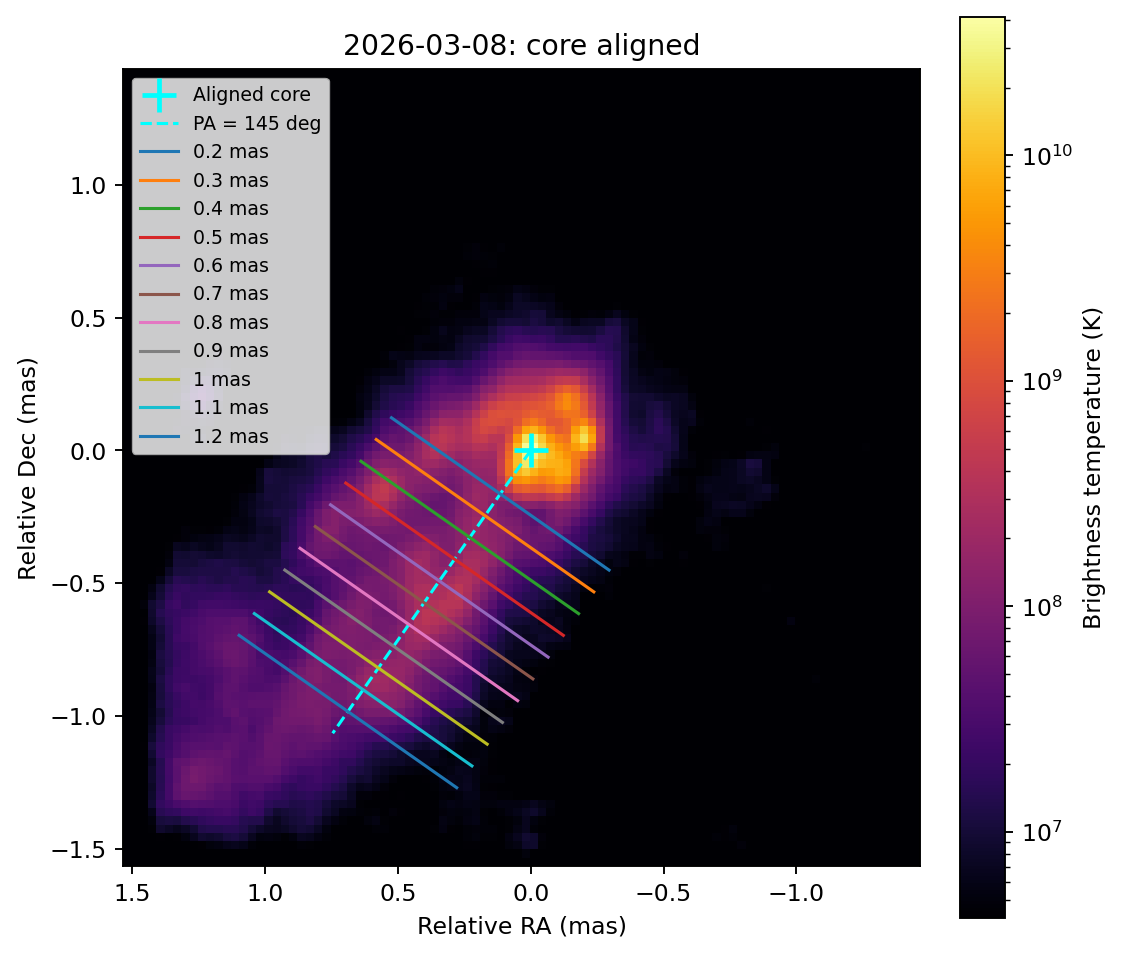

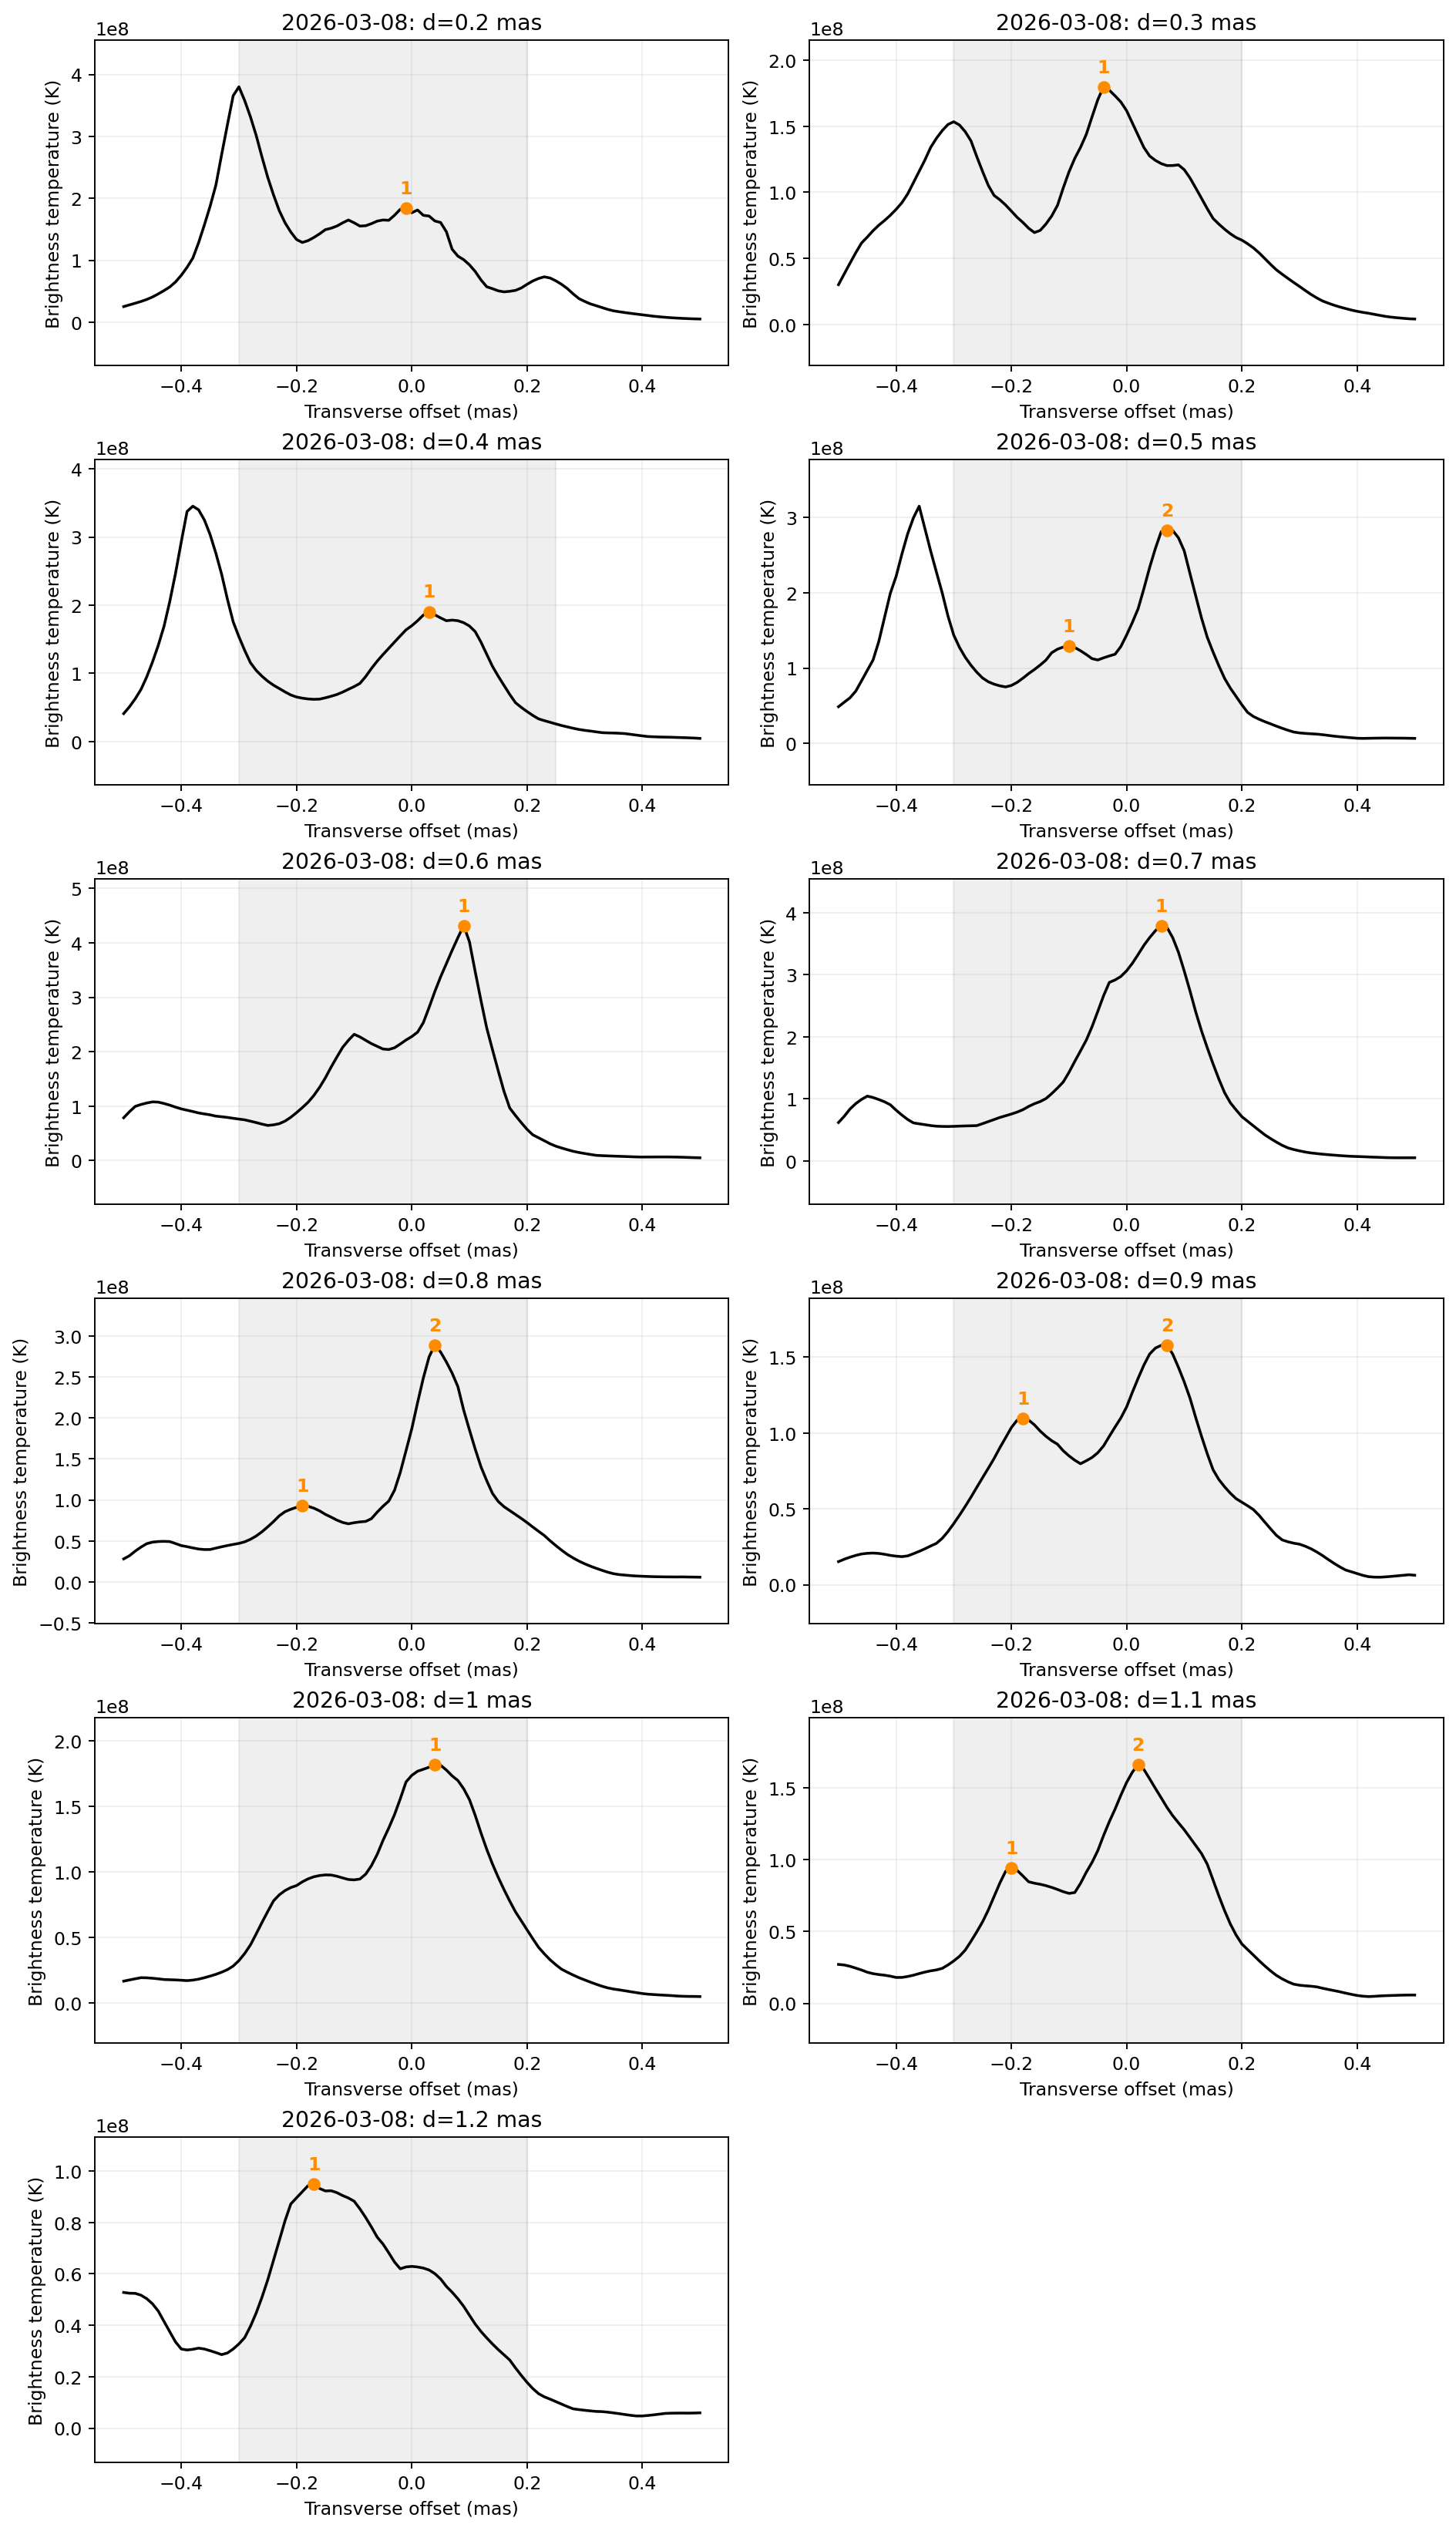


【1/5】2026-03-08
距離の順番： 0.2 / 0.3 / 0.4 / 0.5 / 0.6 / 0.7 / 0.8 / 0.9 / 1 / 1.1 / 1.2 mas
0は選択なし。空欄でEnterなら、その成分は全断面で選択なし。


Jet1B（赤）の番号： 0 1 0 1 0 0 1 1 0 0 0
Jet1A（青）の番号： 1 0 1 2 1 1 2 2 1 2 0


選択を保存しました。


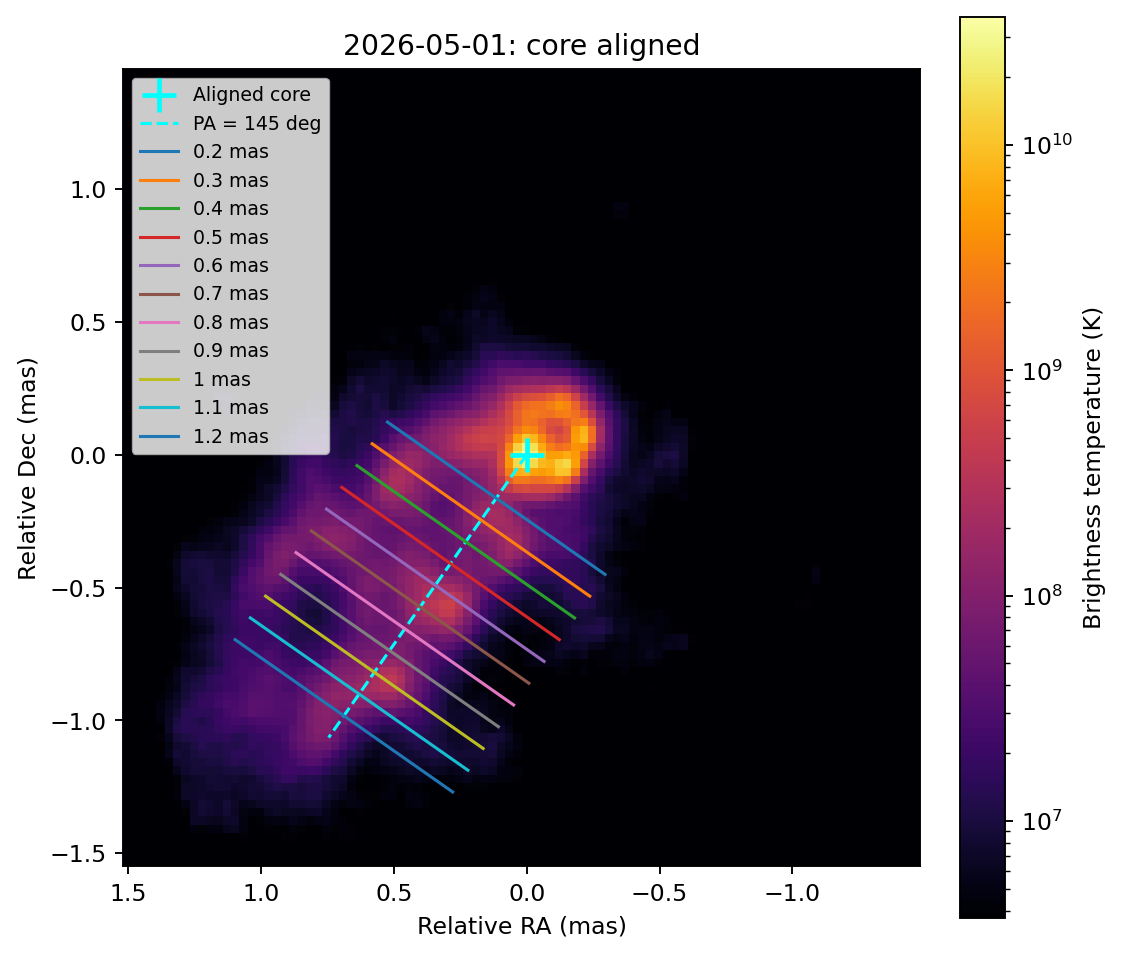

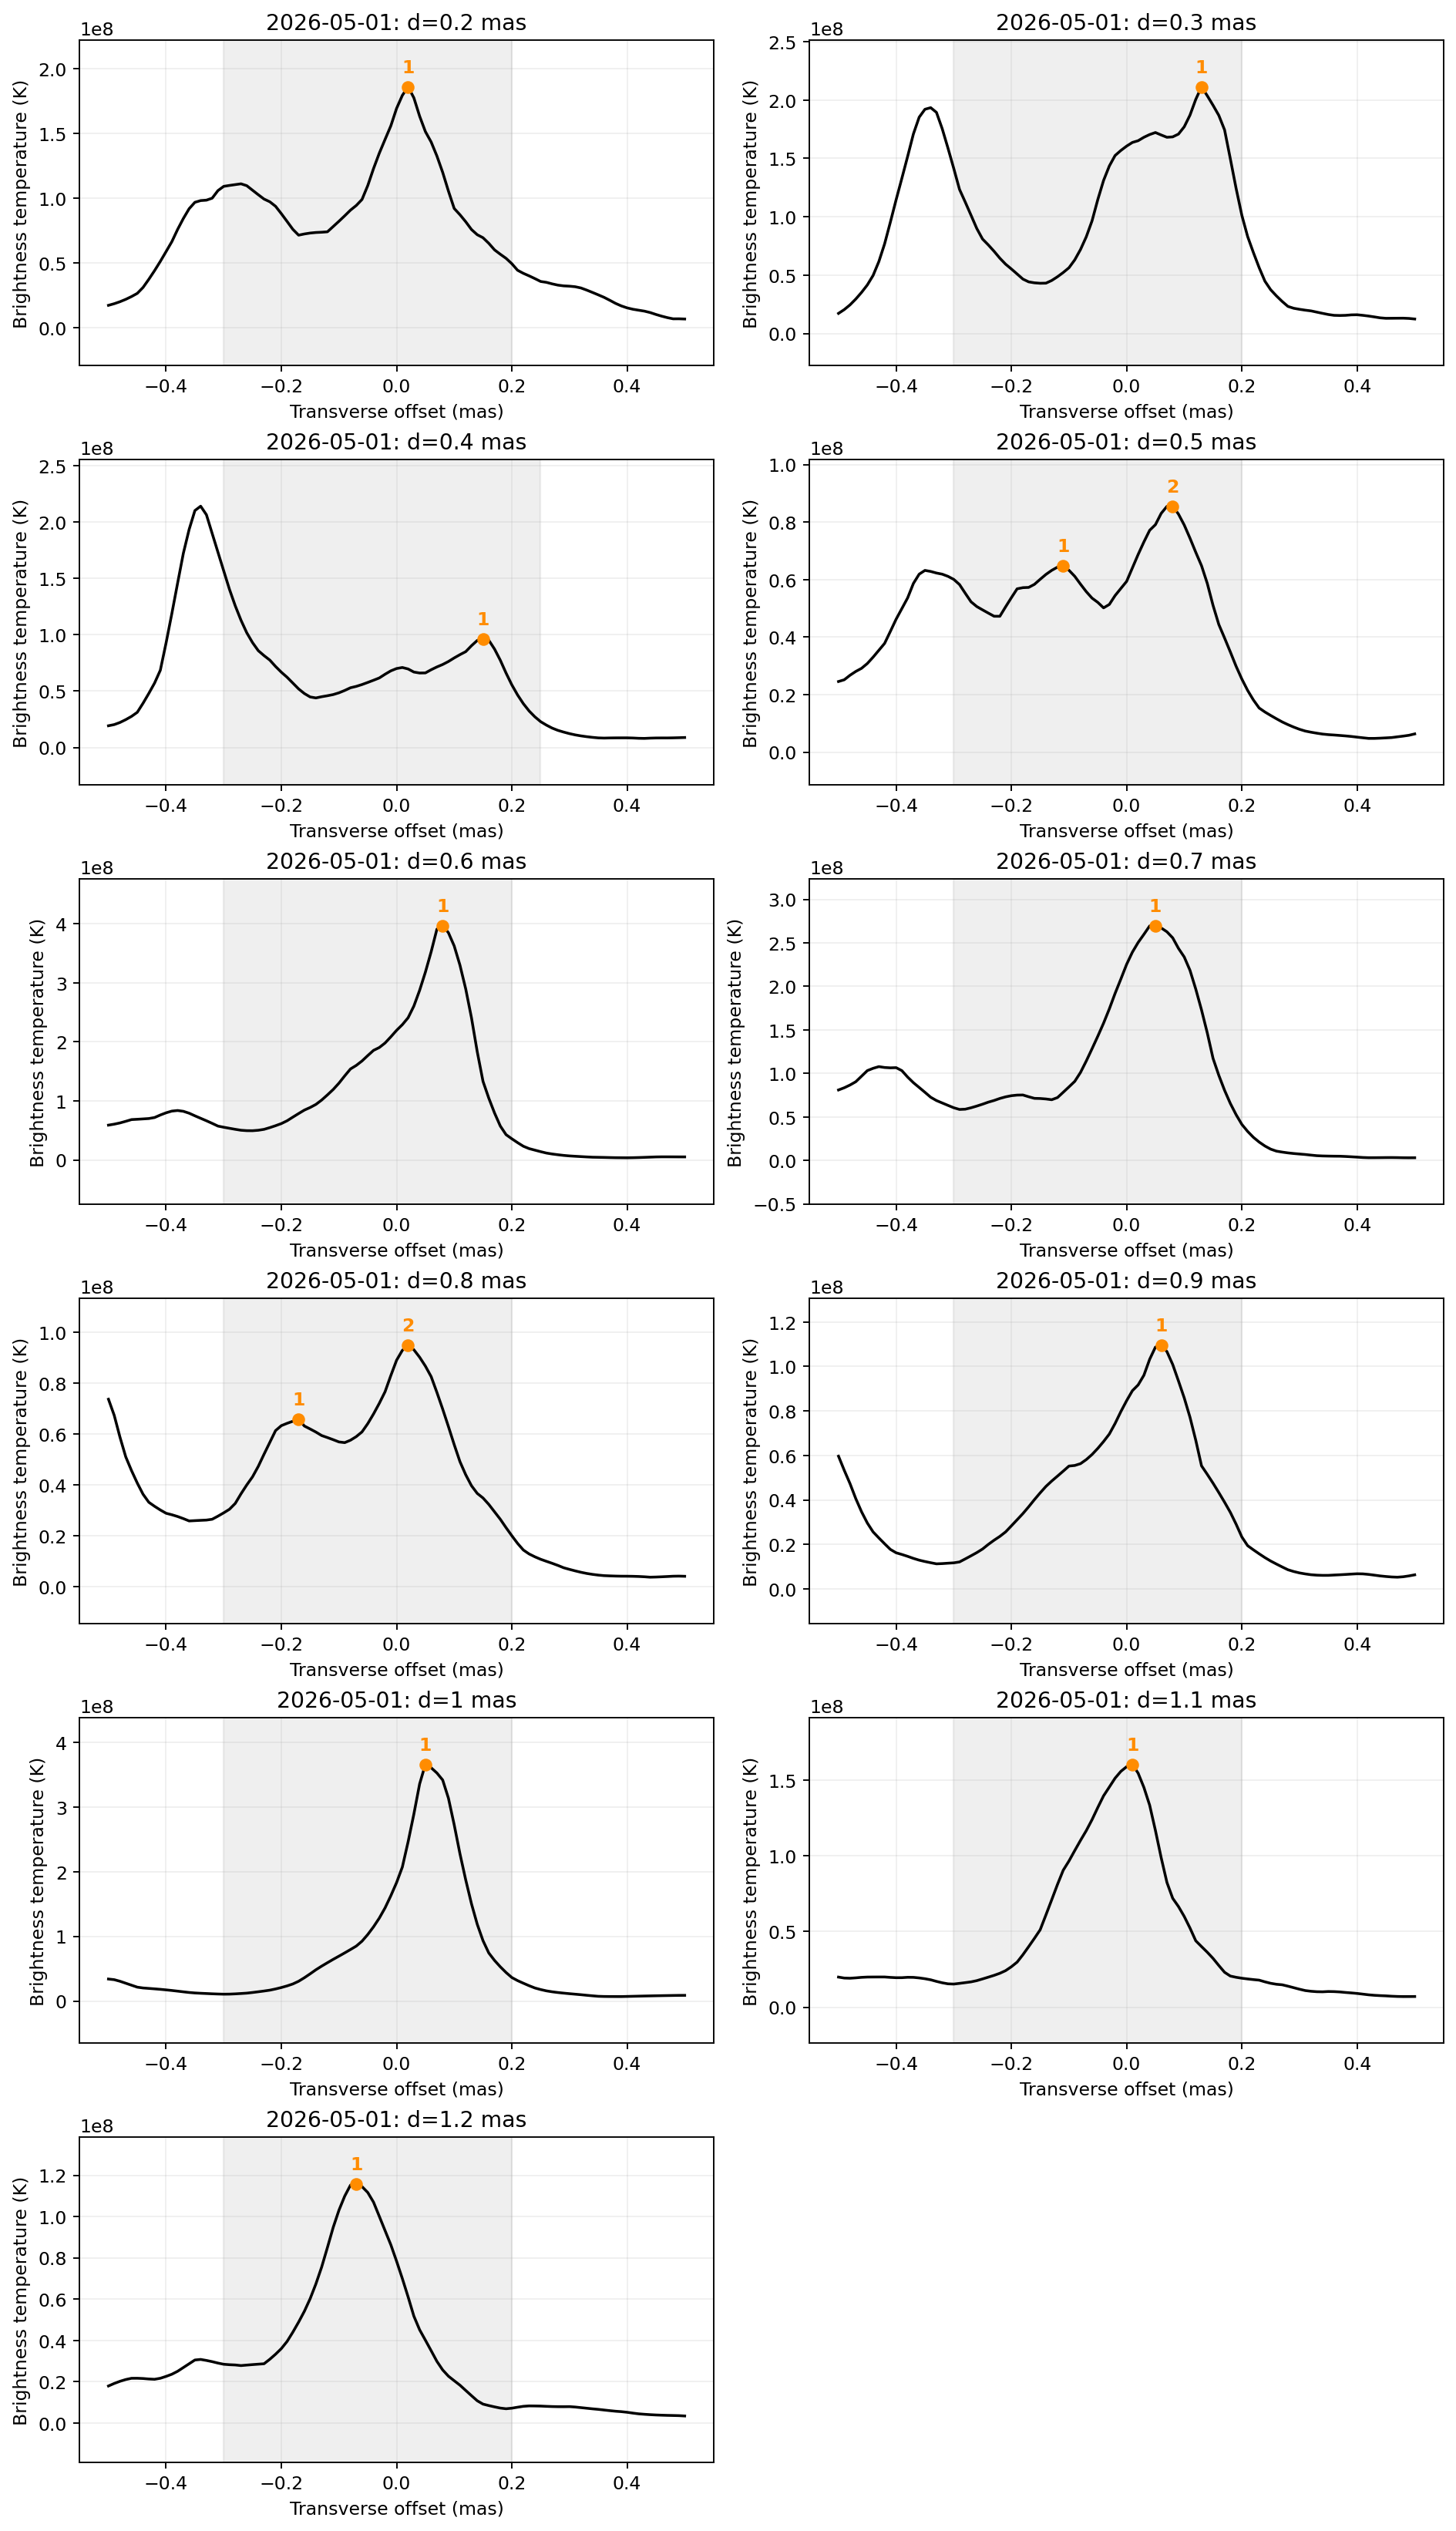


【2/5】2026-05-01
距離の順番： 0.2 / 0.3 / 0.4 / 0.5 / 0.6 / 0.7 / 0.8 / 0.9 / 1 / 1.1 / 1.2 mas
0は選択なし。空欄でEnterなら、その成分は全断面で選択なし。


Jet1B（赤）の番号： 
Jet1A（青）の番号： 1 1 1 2 1 1 2 1 1 1 1


選択を保存しました。


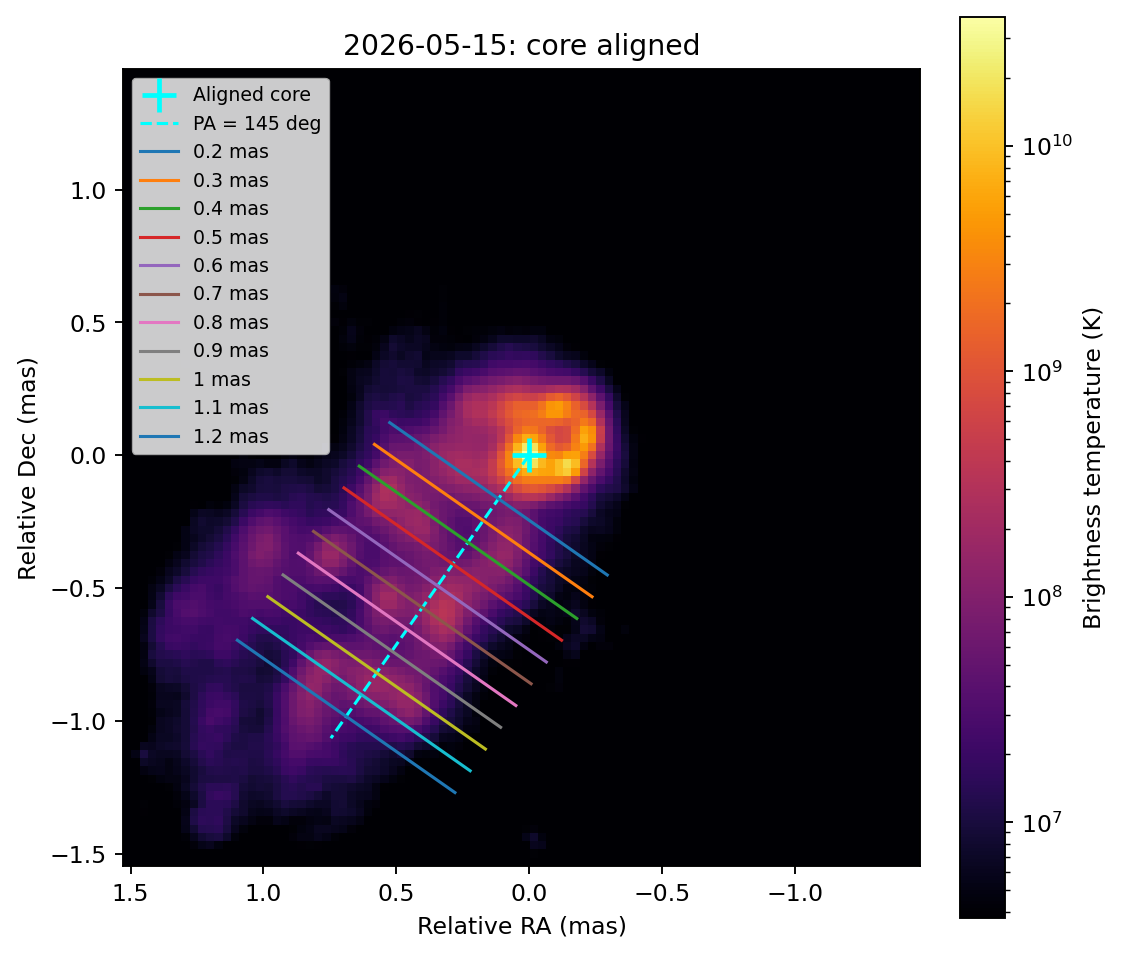

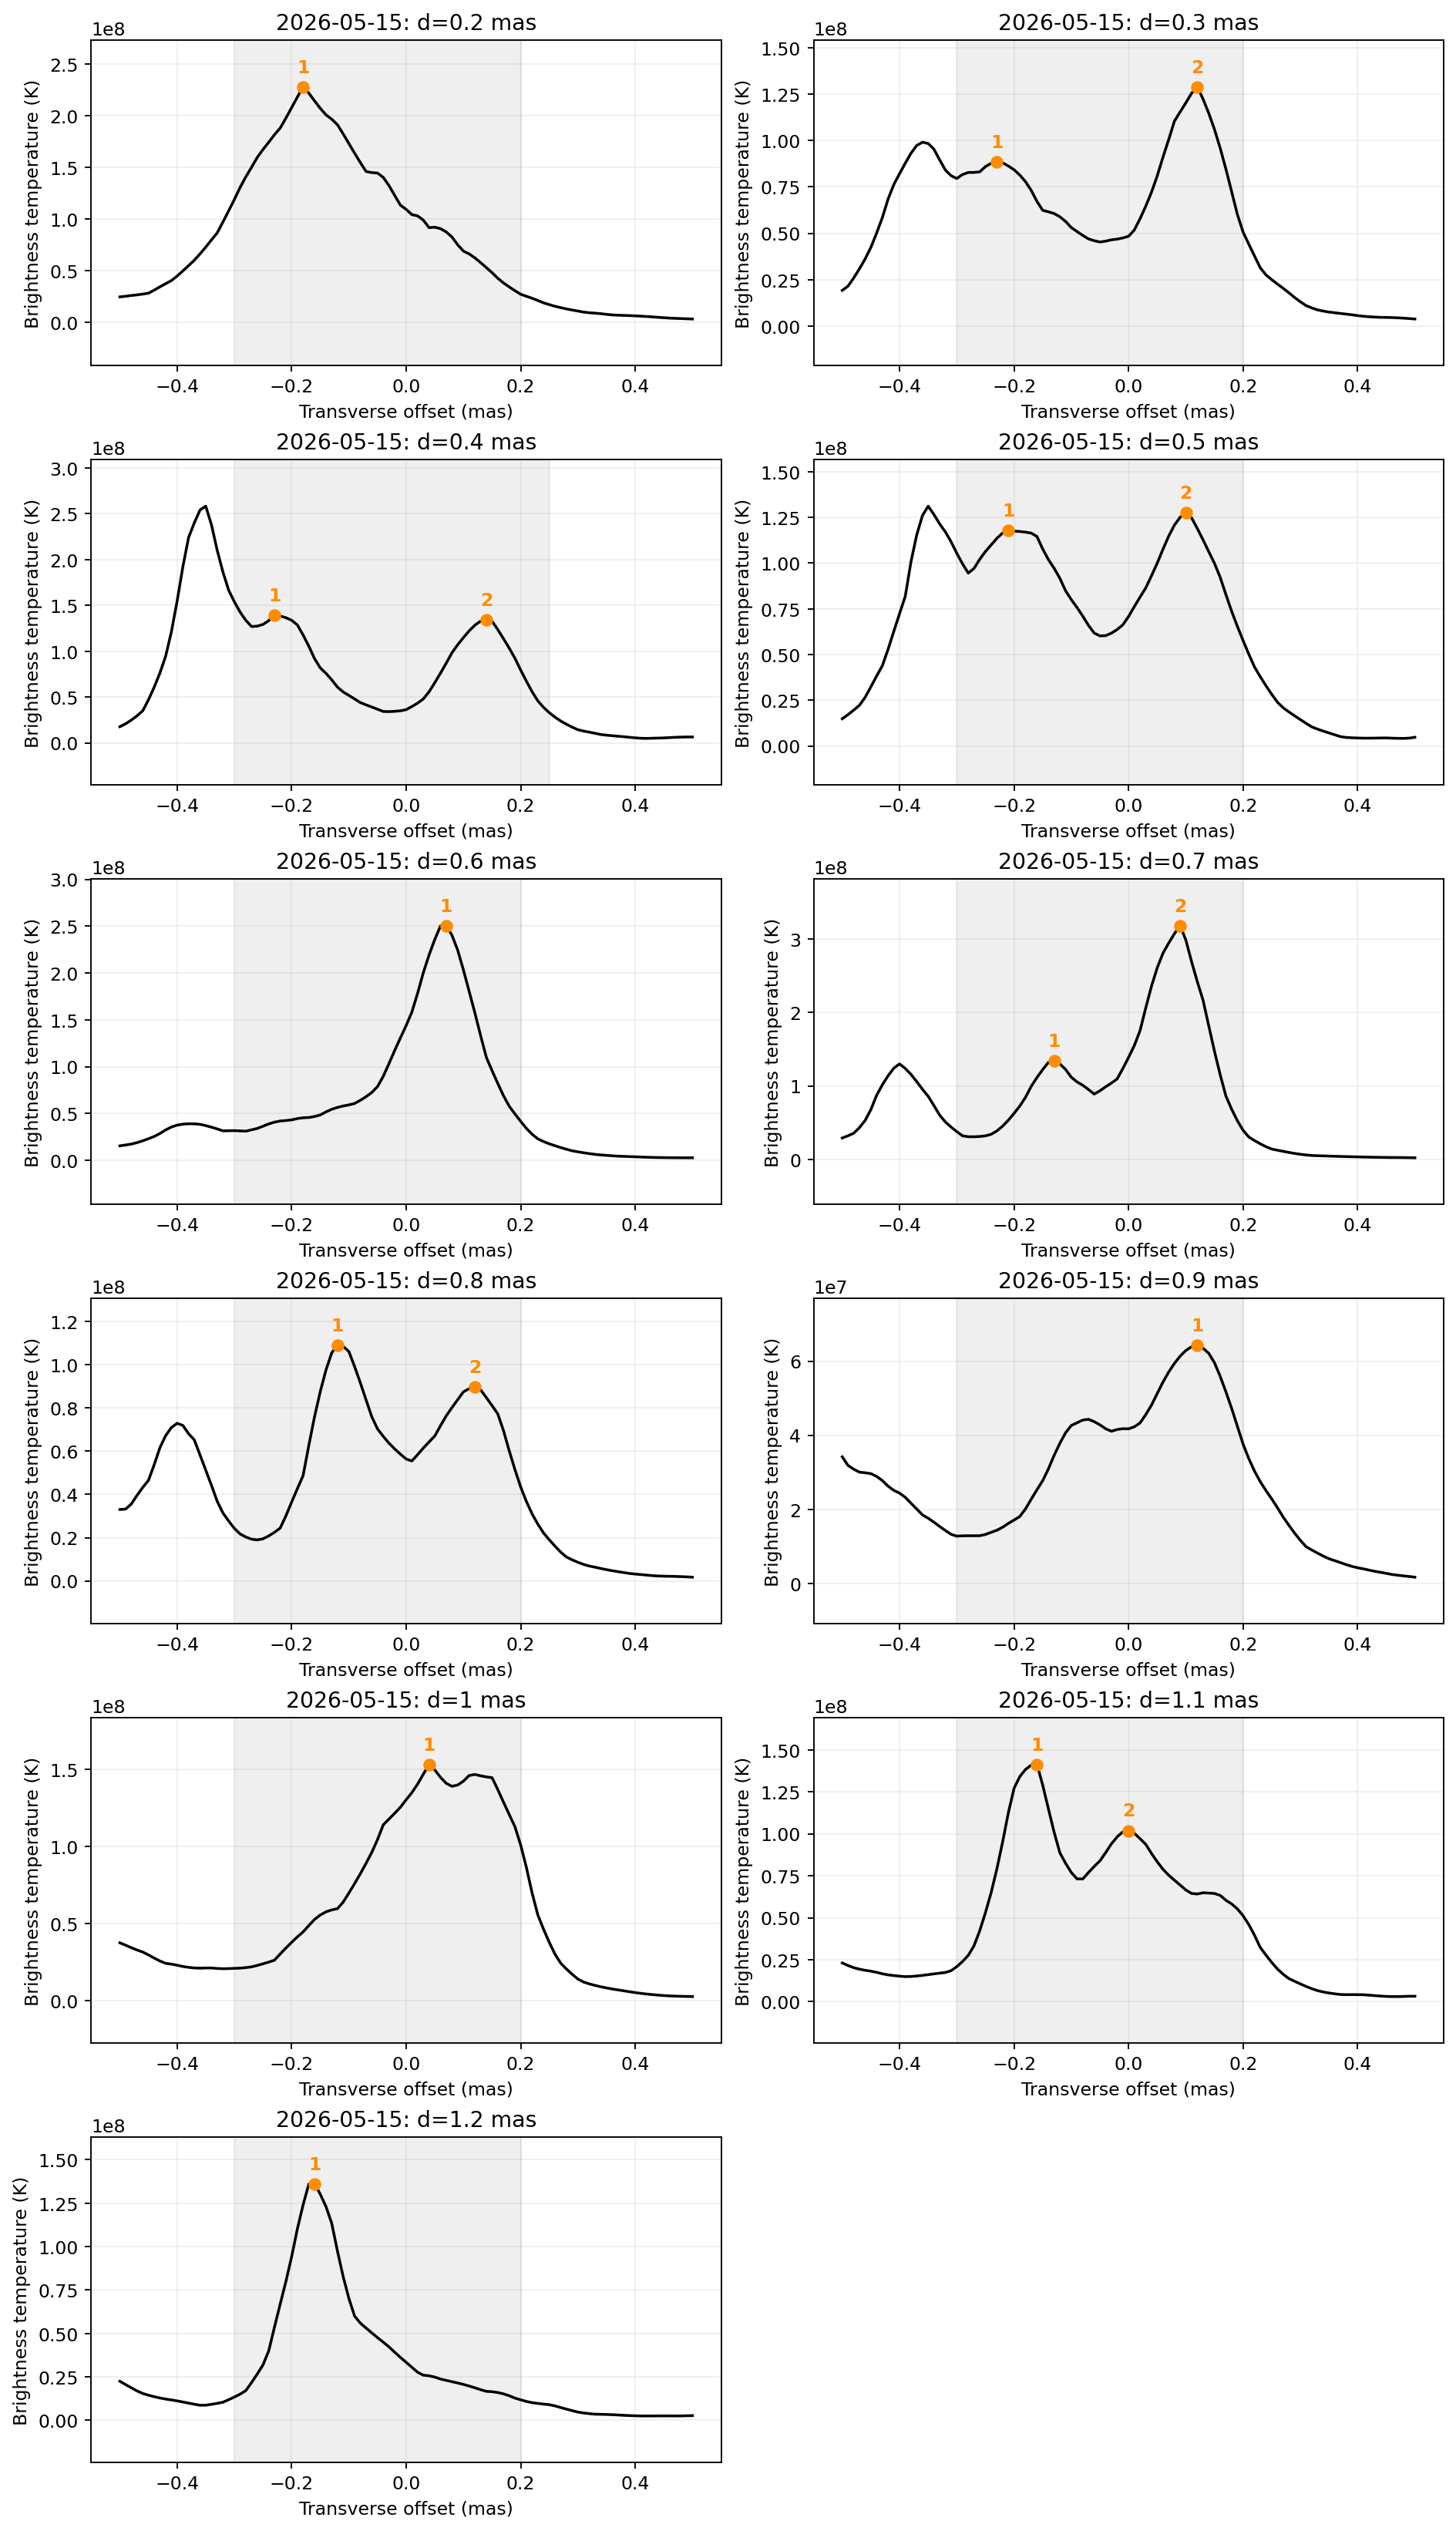


【3/5】2026-05-15
距離の順番： 0.2 / 0.3 / 0.4 / 0.5 / 0.6 / 0.7 / 0.8 / 0.9 / 1 / 1.1 / 1.2 mas
0は選択なし。空欄でEnterなら、その成分は全断面で選択なし。


Jet1B（赤）の番号： 
Jet1A（青）の番号： 0 2 2 2 1 2 2 1 1 2


入力を確認してください：11個の番号を距離順に入力してください
このエポックのB・Aを入力し直してください。


Jet1B（赤）の番号： 
Jet1A（青）の番号： 0 2 2 2 1 2 2 1 1 2 0


選択を保存しました。


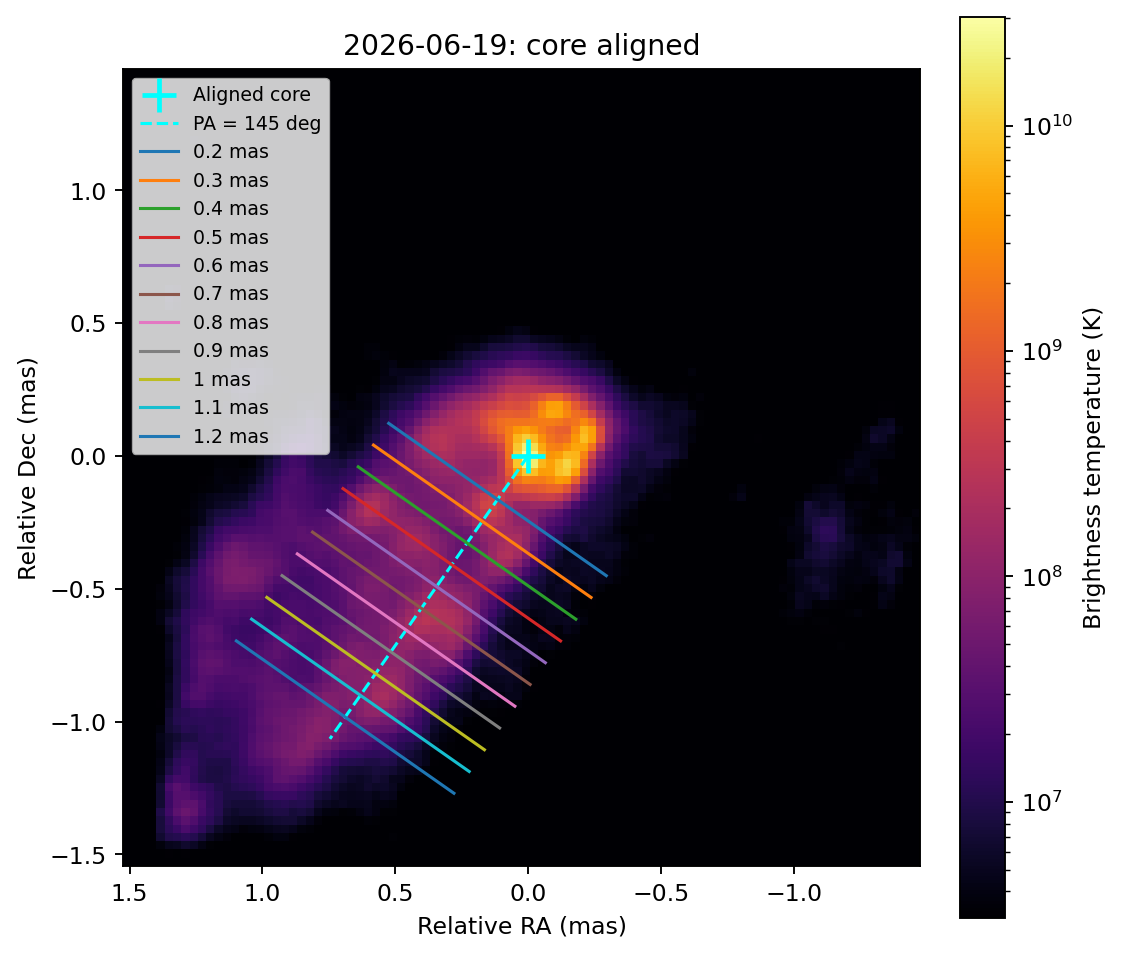

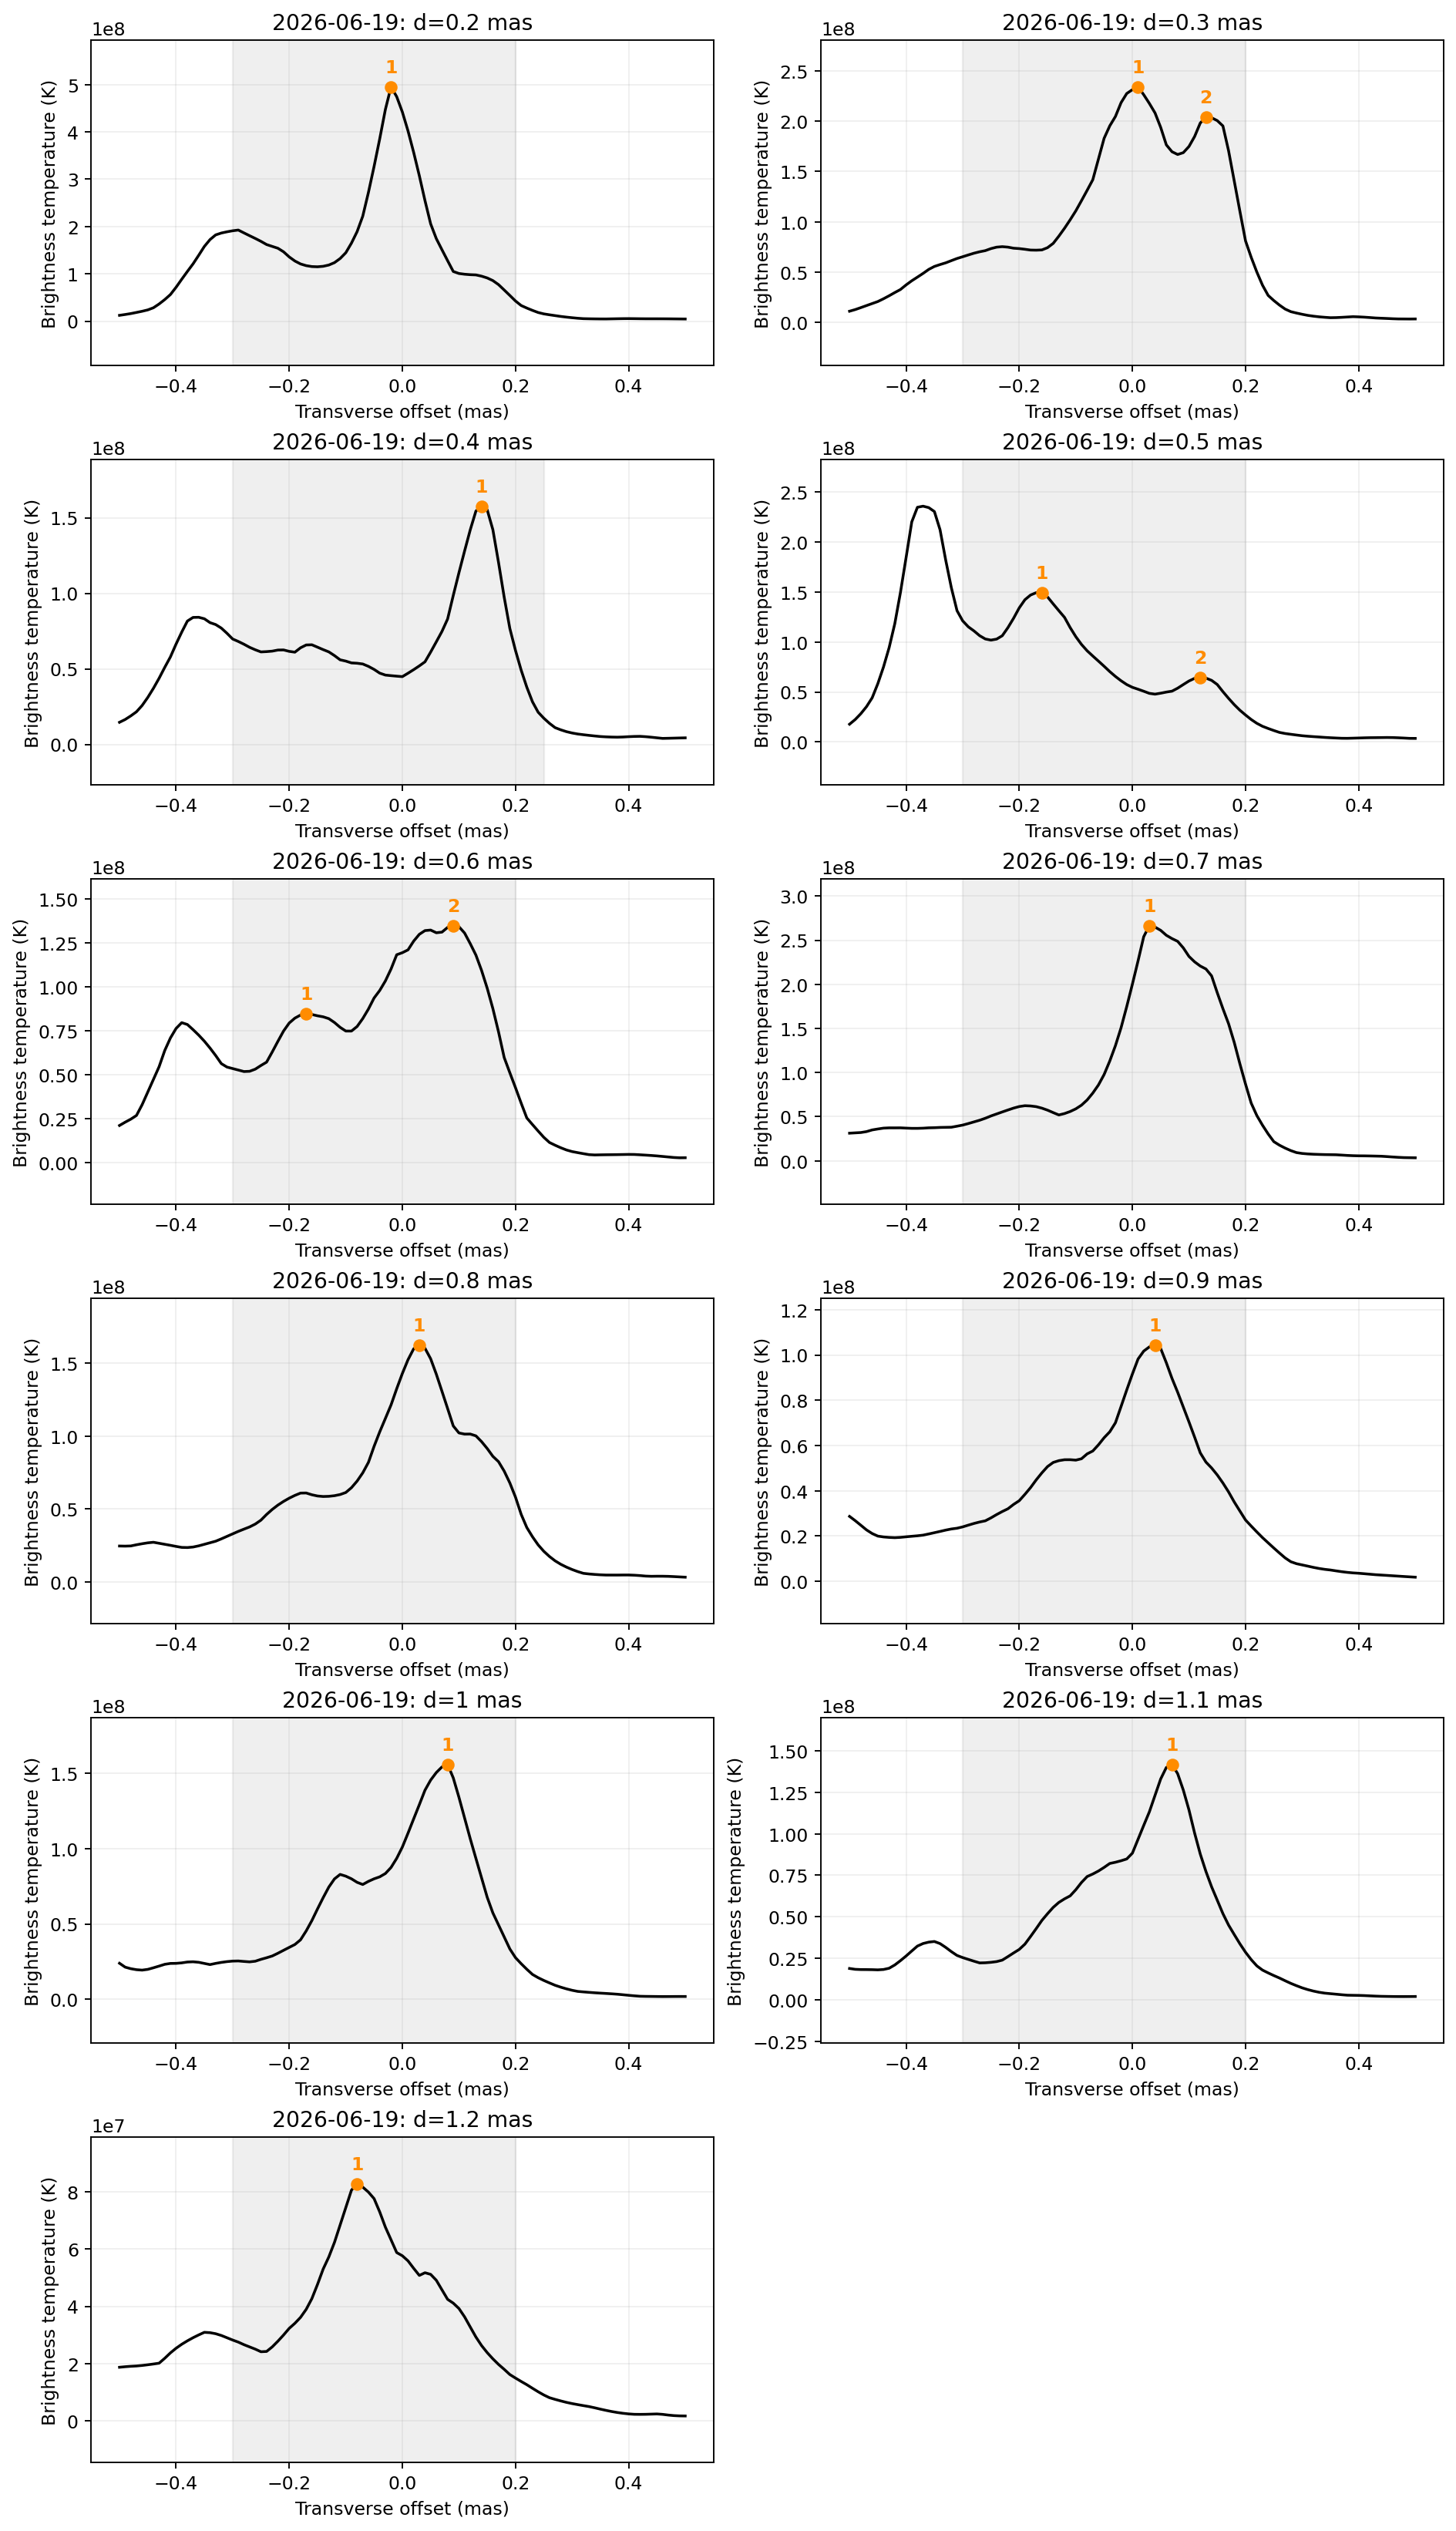


【4/5】2026-06-19
距離の順番： 0.2 / 0.3 / 0.4 / 0.5 / 0.6 / 0.7 / 0.8 / 0.9 / 1 / 1.1 / 1.2 mas
0は選択なし。空欄でEnterなら、その成分は全断面で選択なし。


Jet1B（赤）の番号： 1 1 0 1 1 0 0 0 0 0 0
Jet1A（青）の番号： 0 2 1 2 2 1 1 1 1 1 1


選択を保存しました。


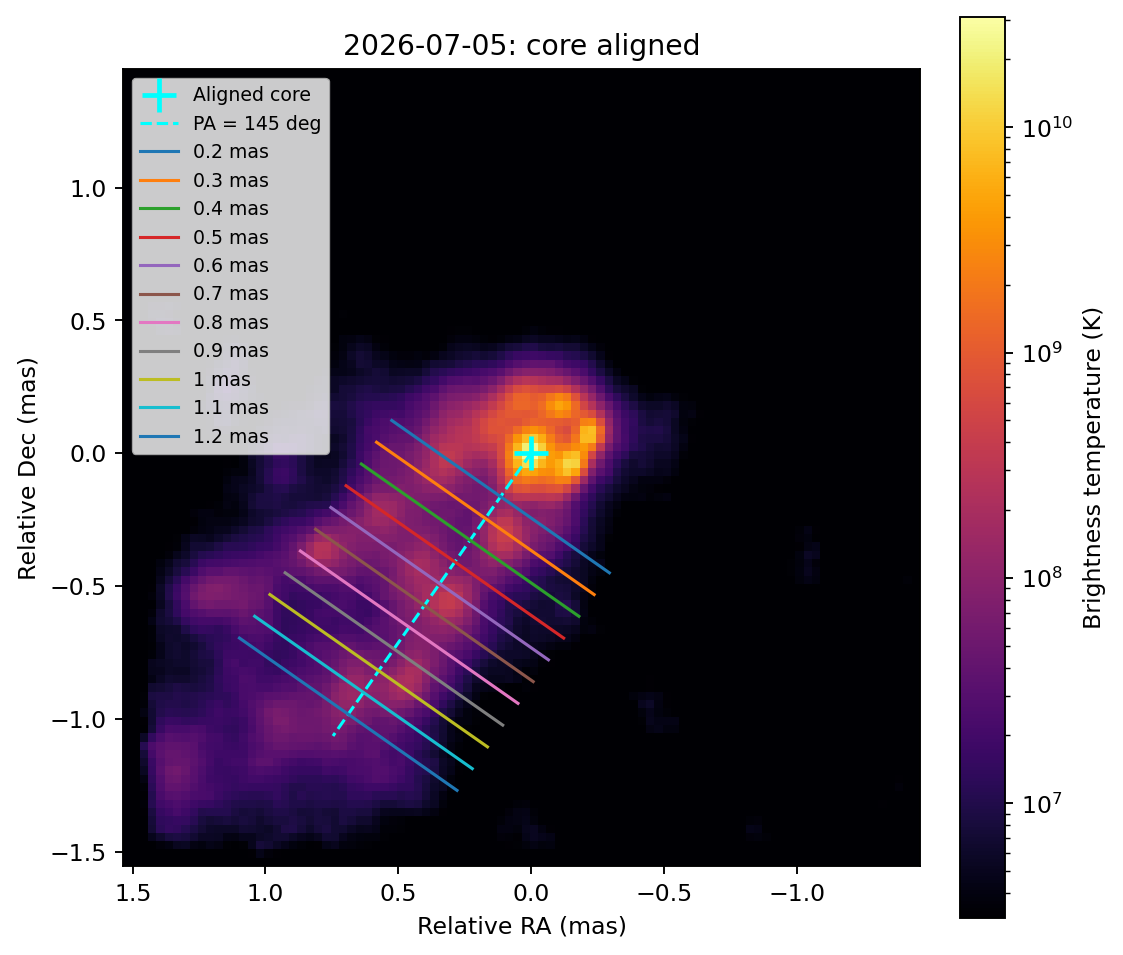

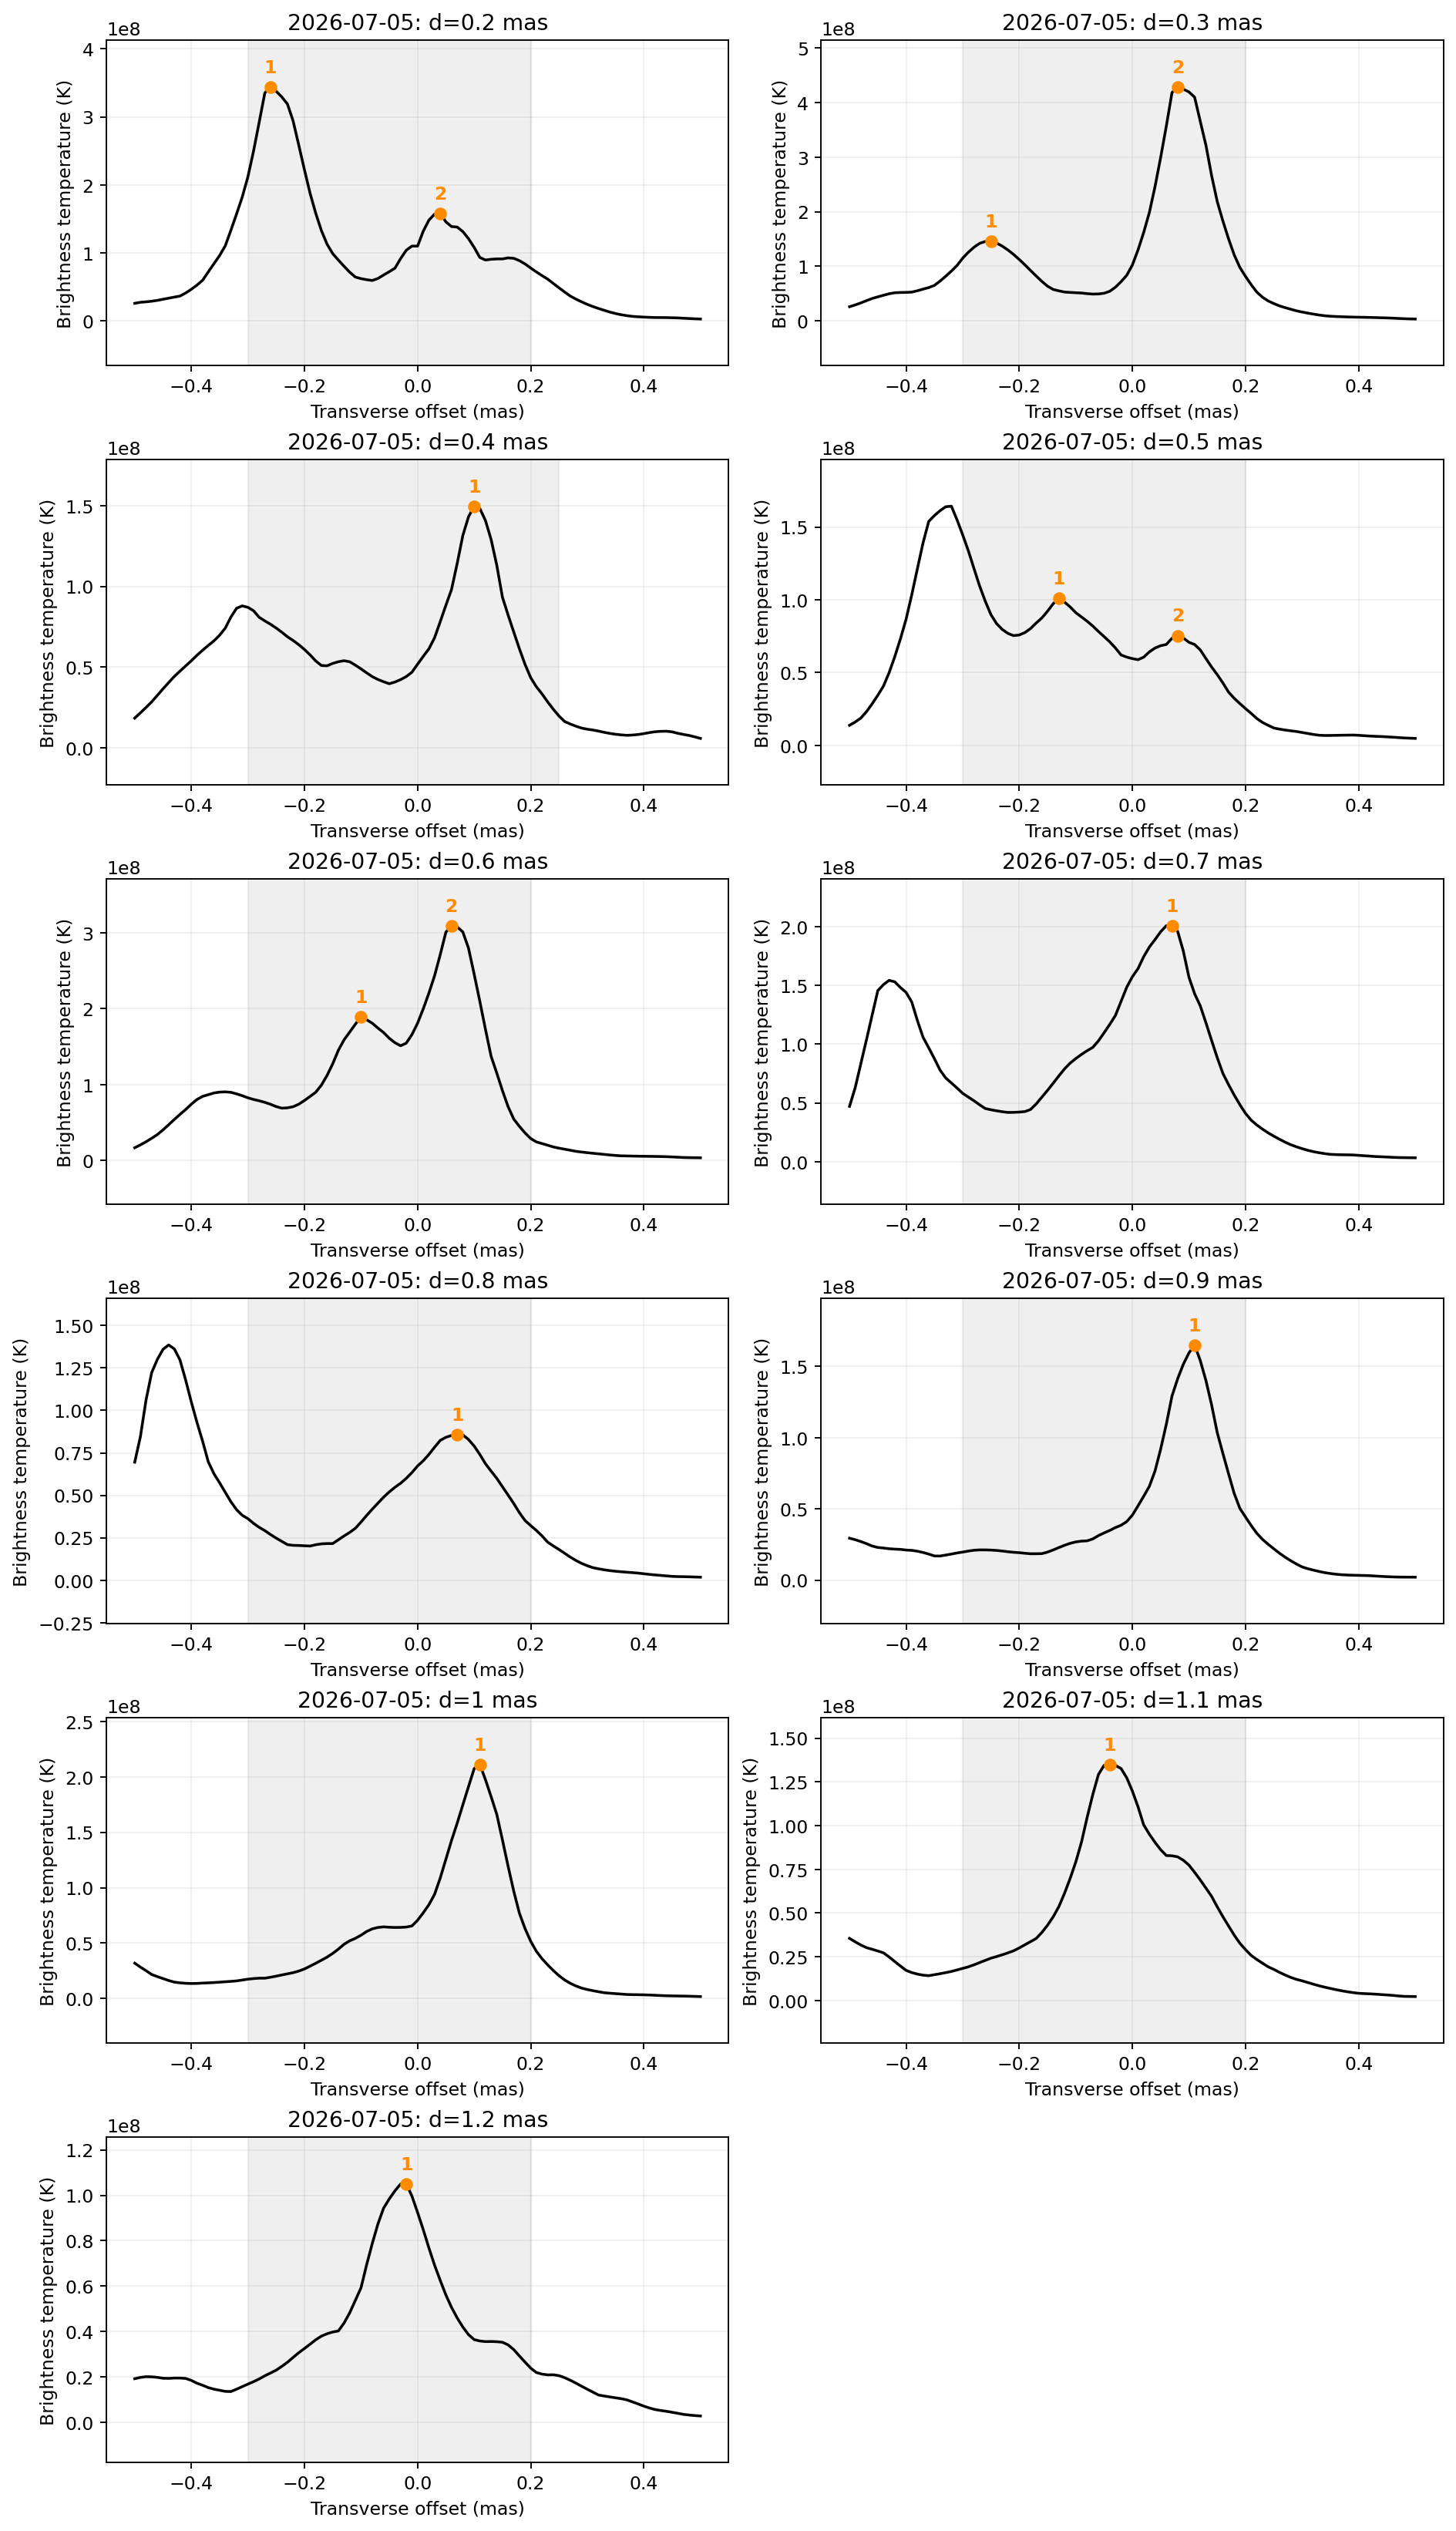


【5/5】2026-07-05
距離の順番： 0.2 / 0.3 / 0.4 / 0.5 / 0.6 / 0.7 / 0.8 / 0.9 / 1 / 1.1 / 1.2 mas
0は選択なし。空欄でEnterなら、その成分は全断面で選択なし。


Jet1B（赤）の番号： 
Jet1A（青）の番号： 2 2 1 2 2 1 1 1 1  


入力を確認してください：11個の番号を距離順に入力してください
このエポックのB・Aを入力し直してください。


Jet1B（赤）の番号： 
Jet1A（青）の番号： 2 2 1 2 2 1 1 1 1 1 1 1


入力を確認してください：11個の番号を距離順に入力してください
このエポックのB・Aを入力し直してください。


Jet1B（赤）の番号： 
Jet1A（青）の番号： 2 2 1 2 2 1 1 1 1 1 1


選択を保存しました。

全エポックの選択が完了しました。
2026-03-08: core=(48.609, 49.571)


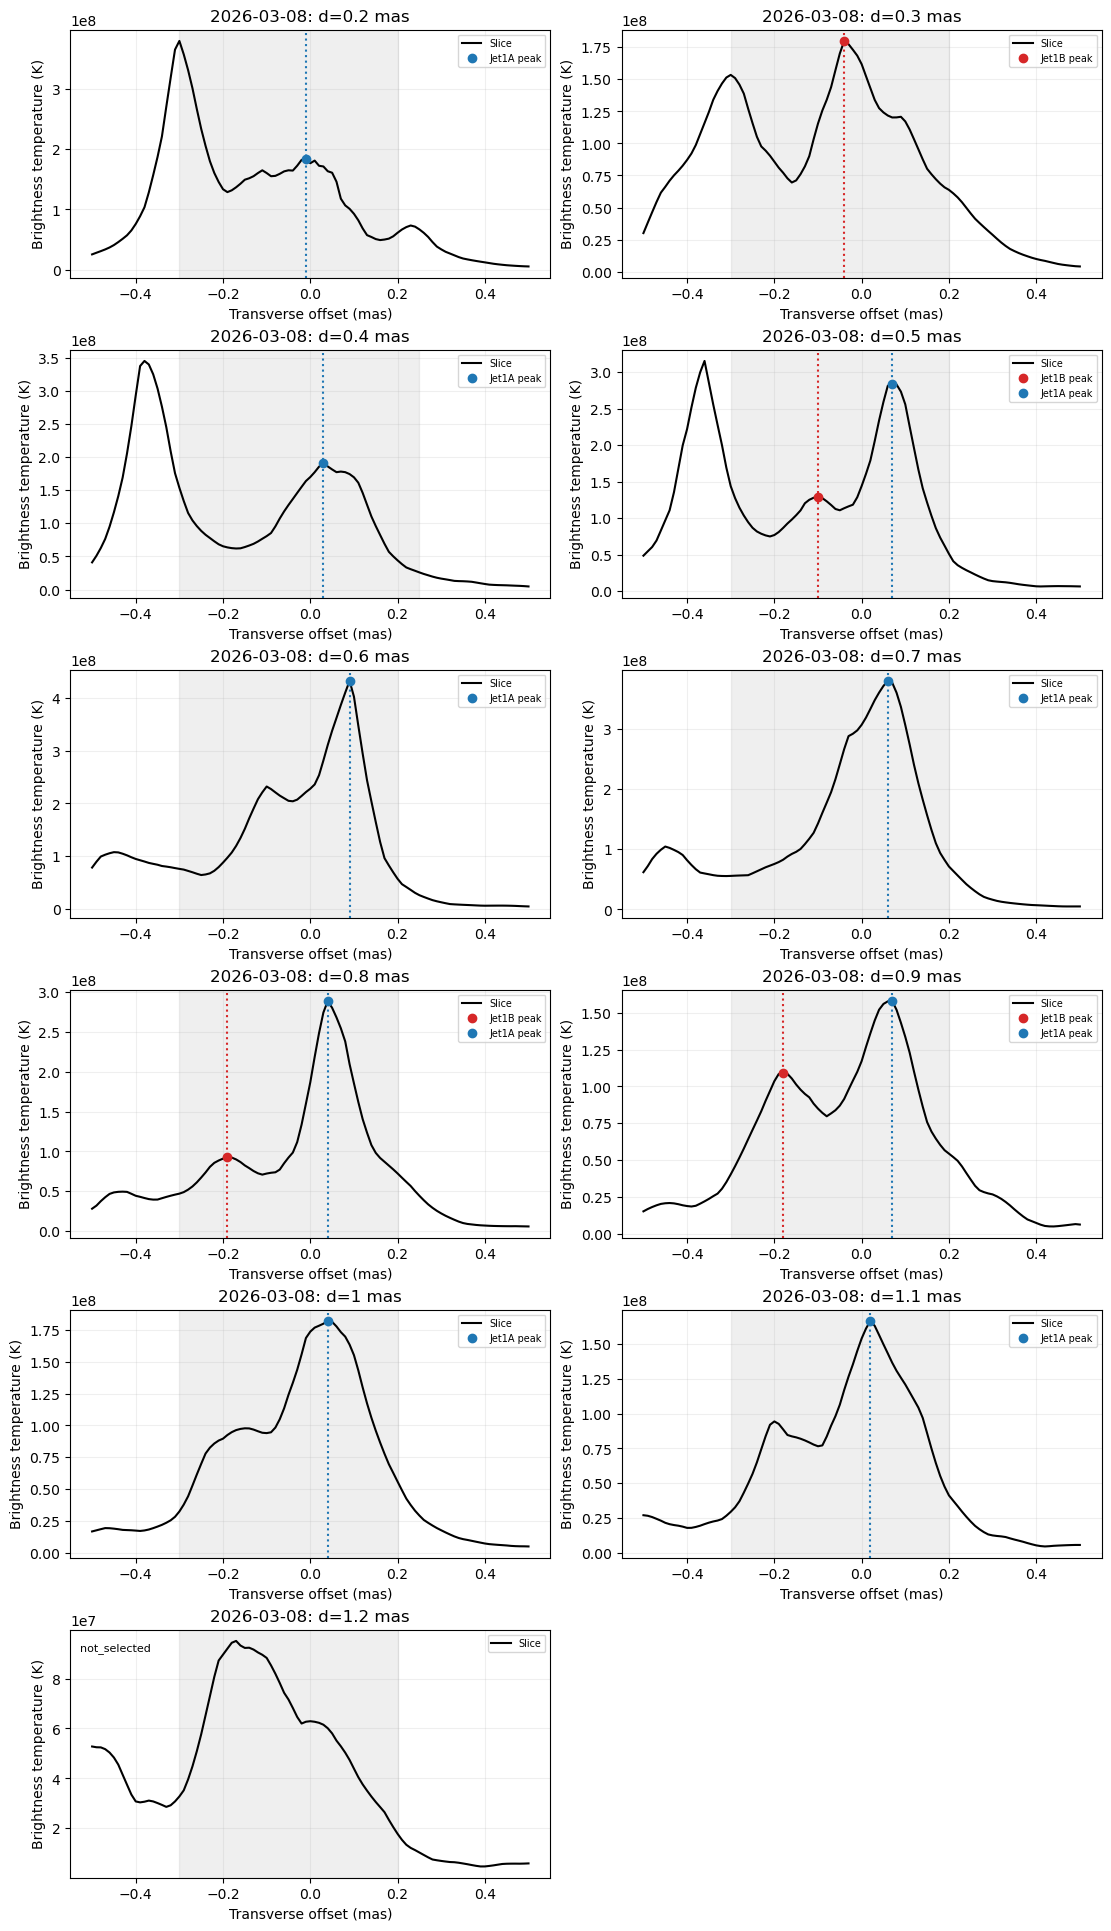

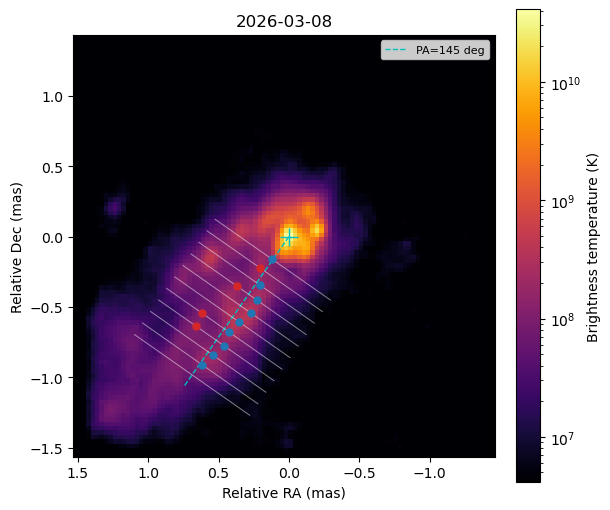

2026-05-01: core=(48.124, 49.053)


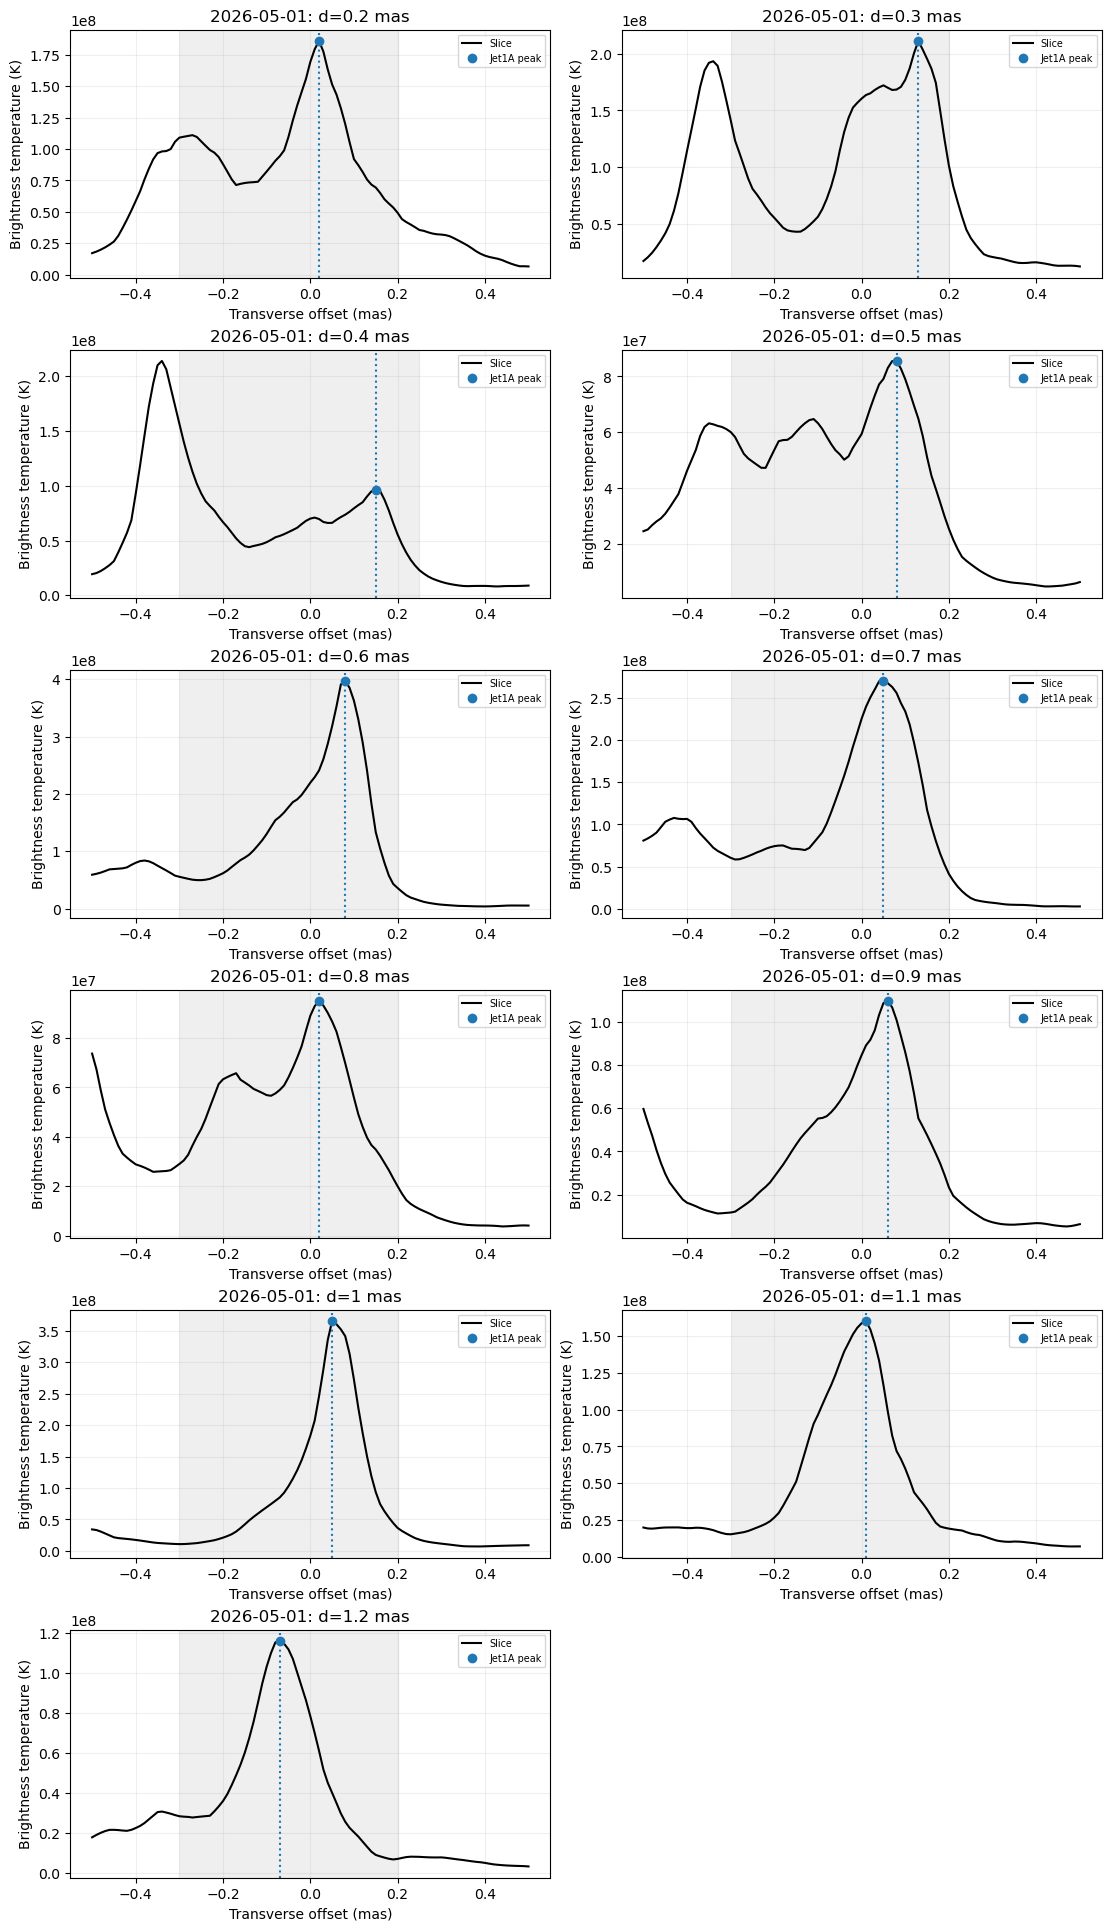

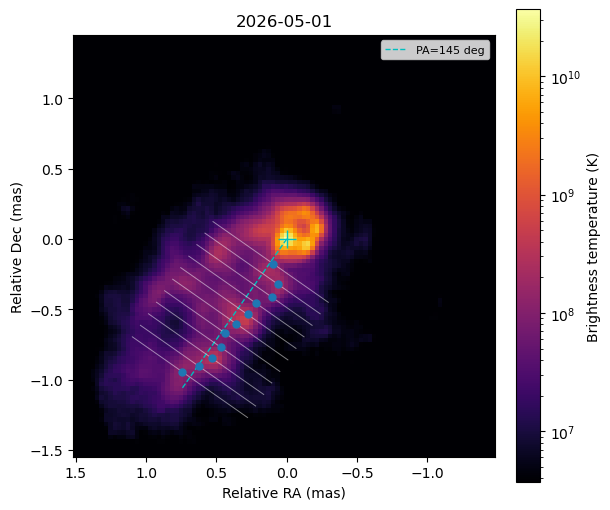

2026-05-15: core=(48.396, 48.985)


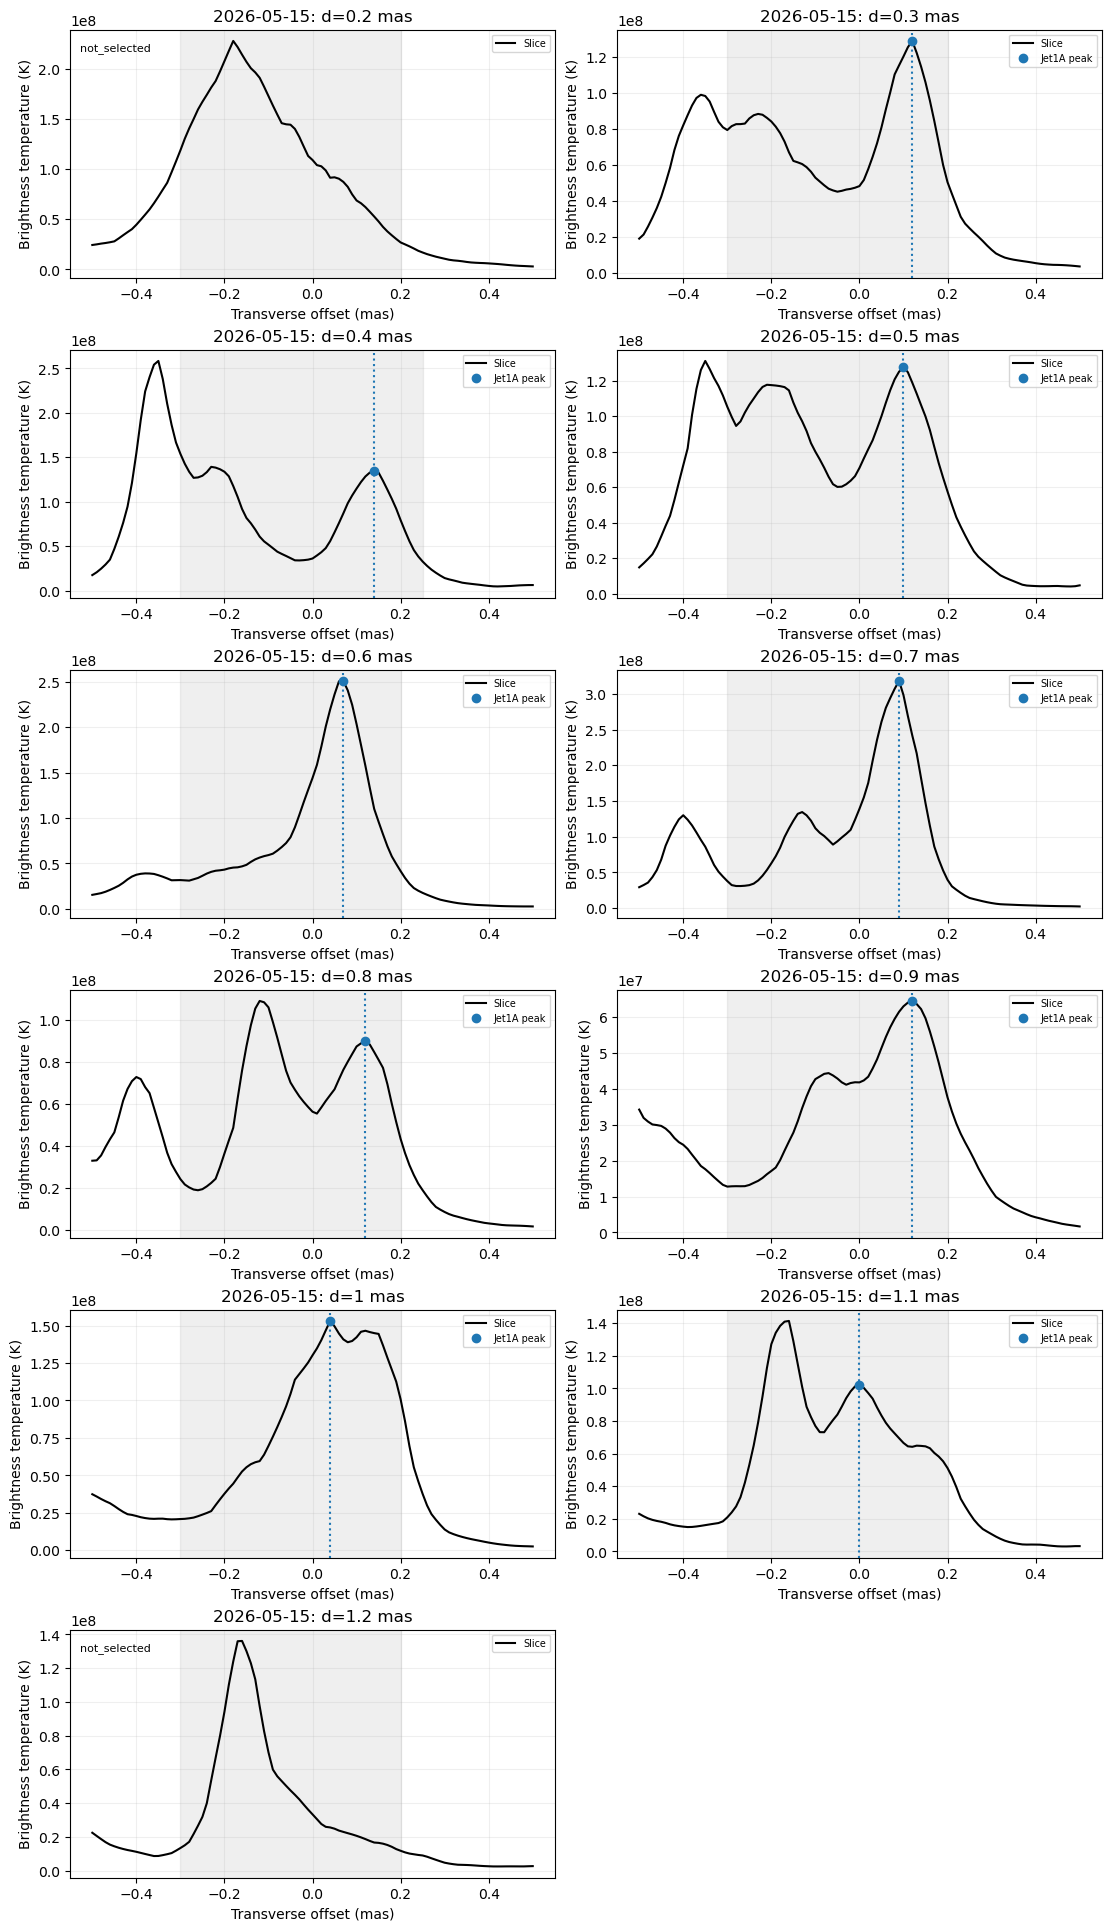

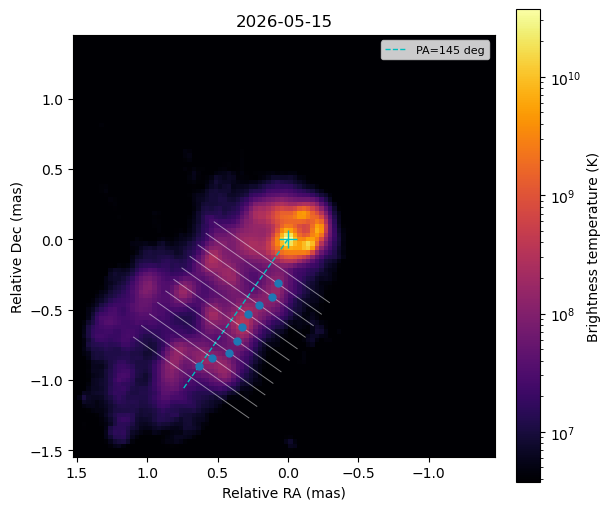

2026-06-19: core=(48.277, 48.900)


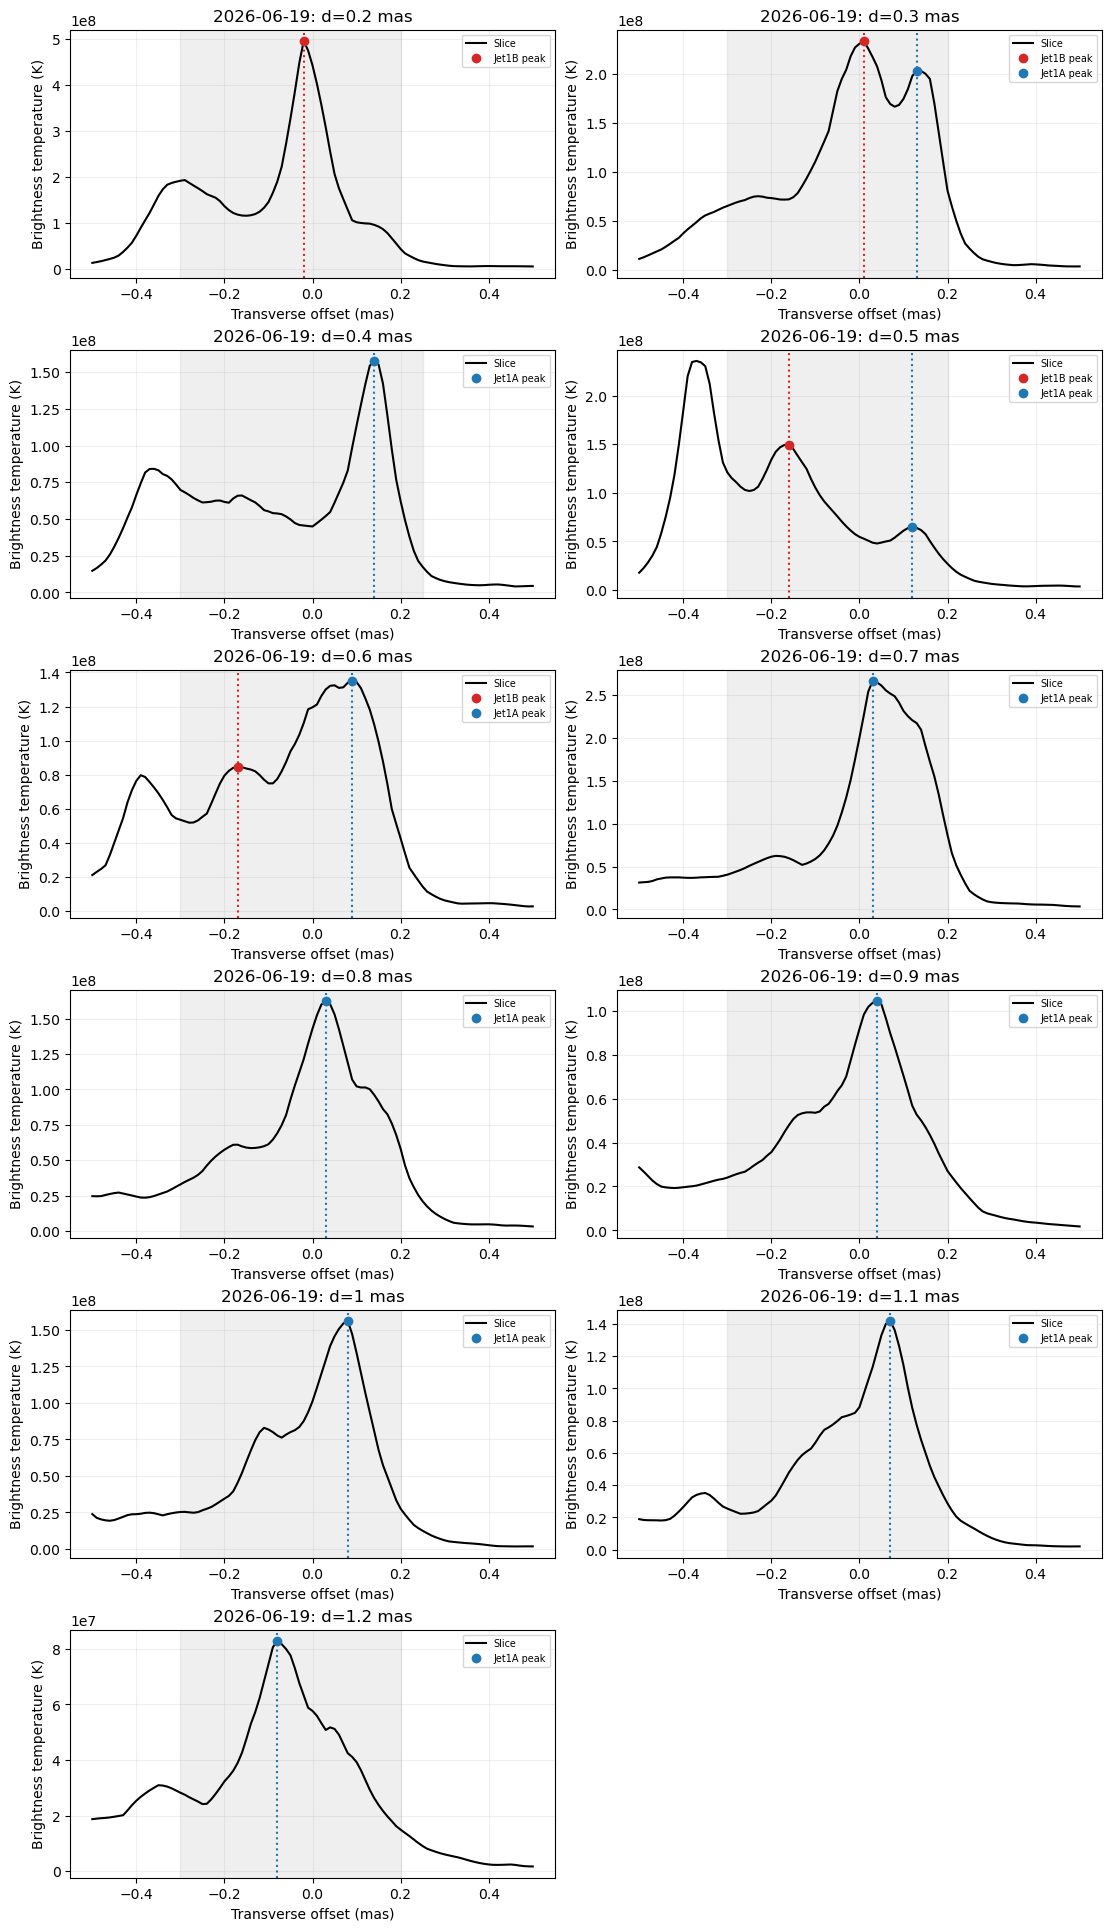

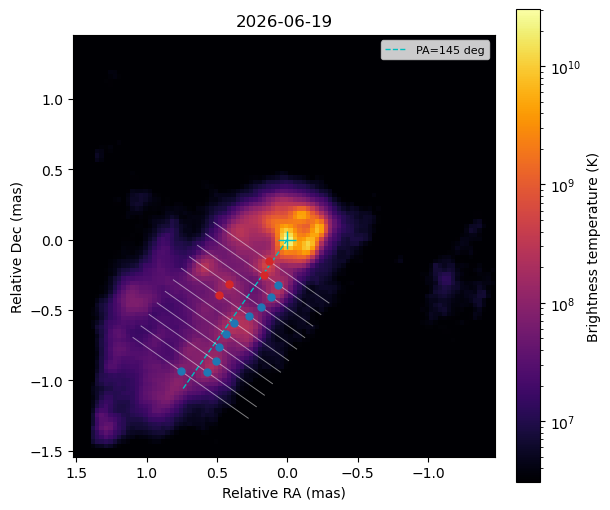

2026-07-05: core=(48.649, 49.245)


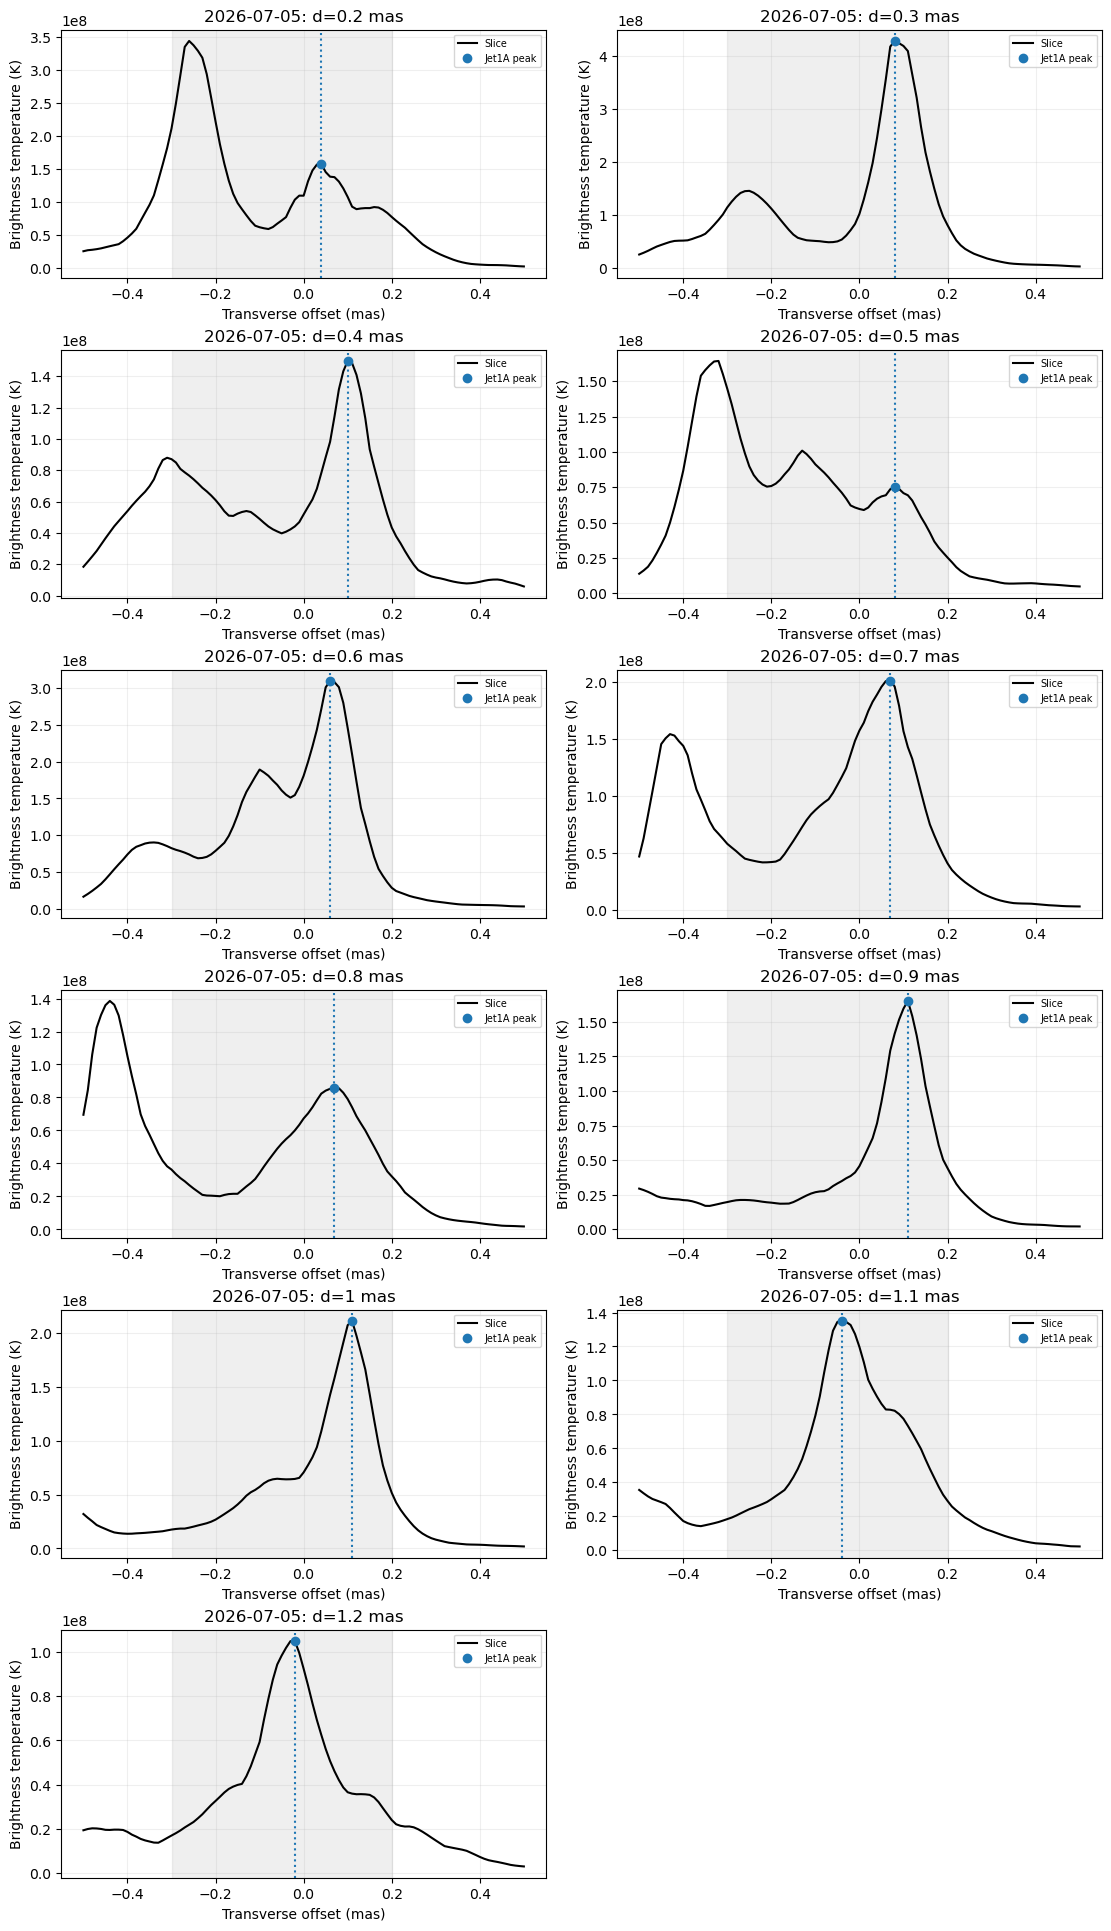

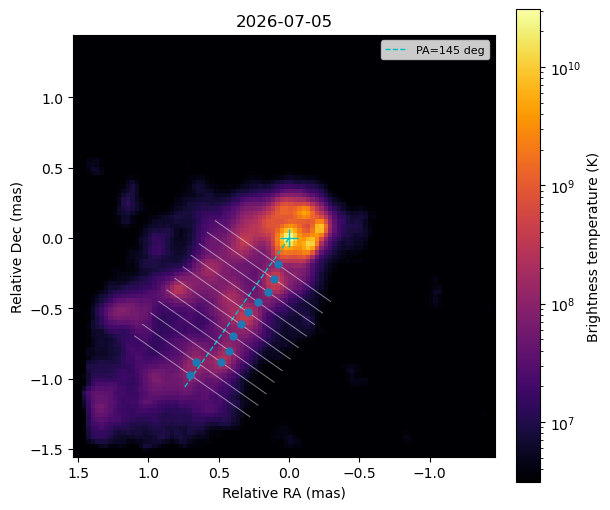

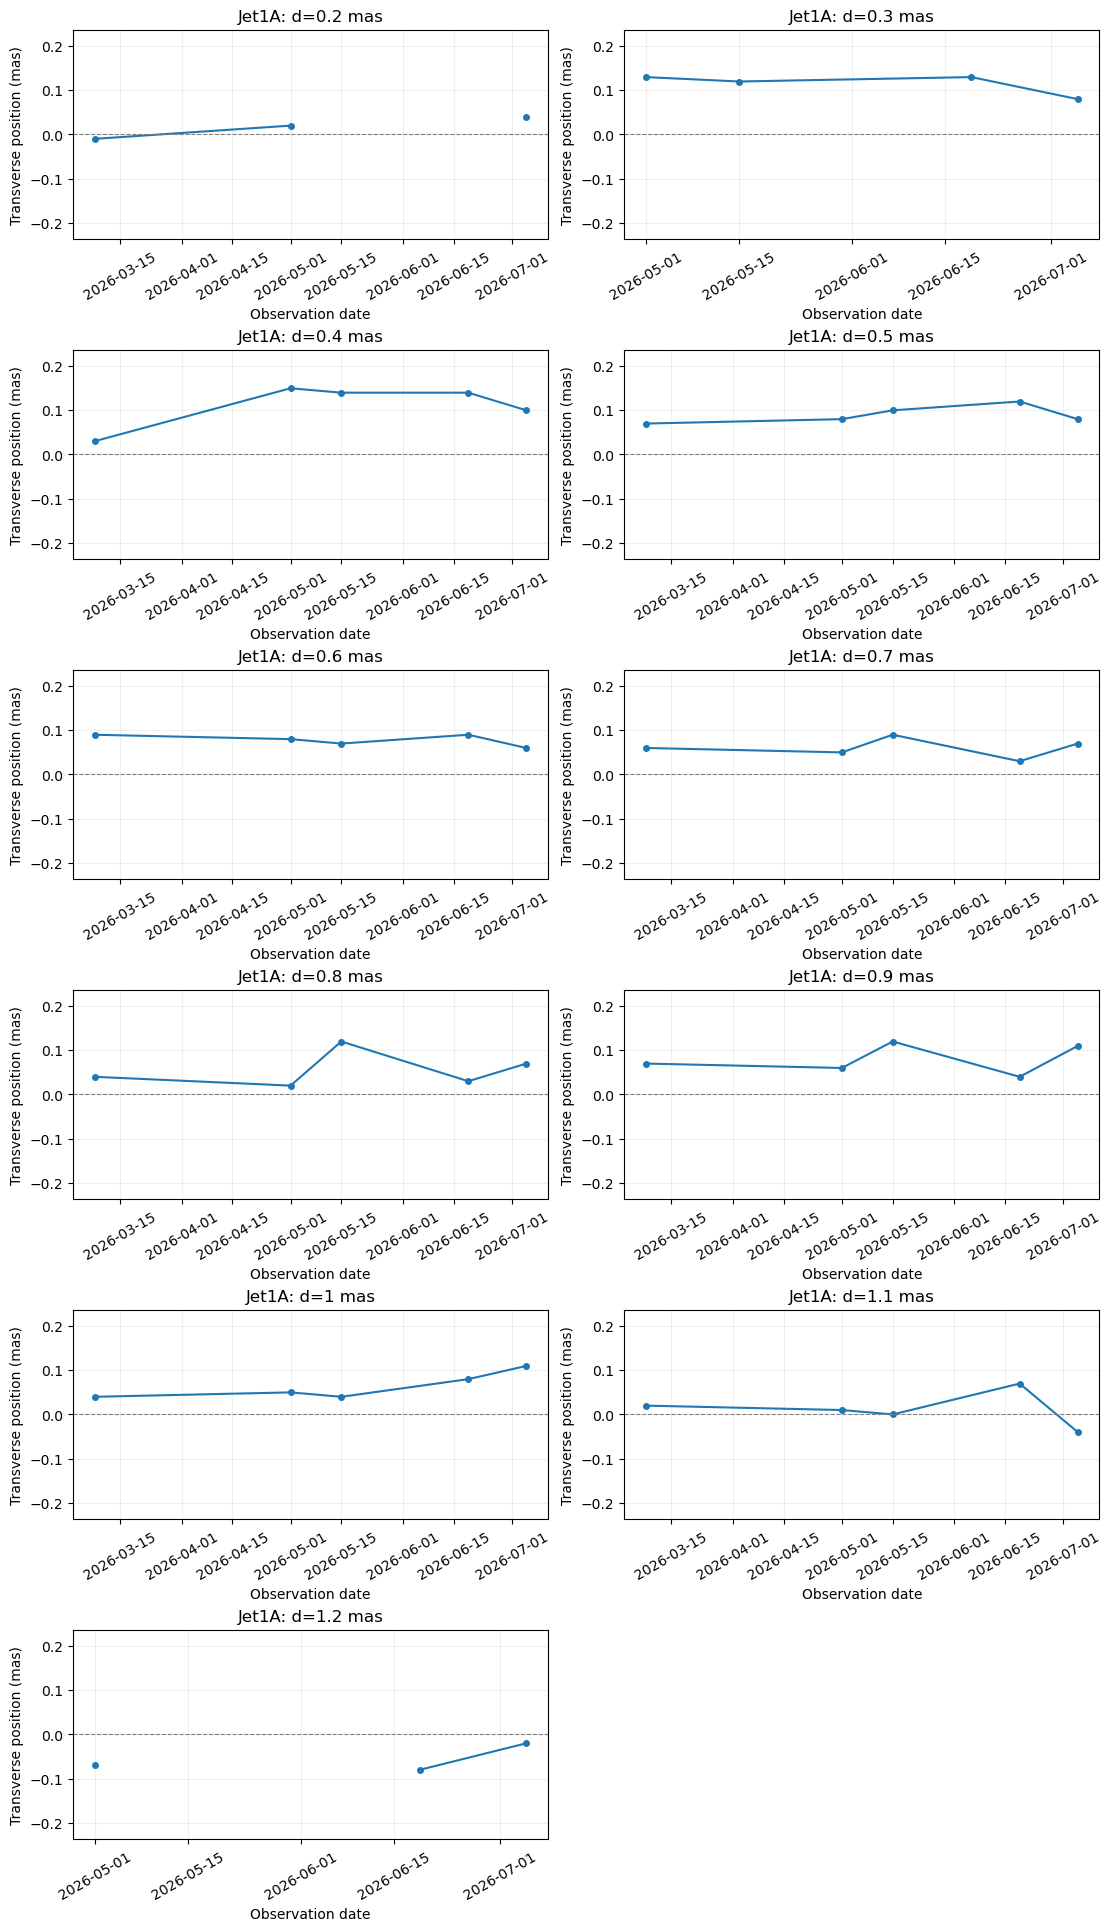

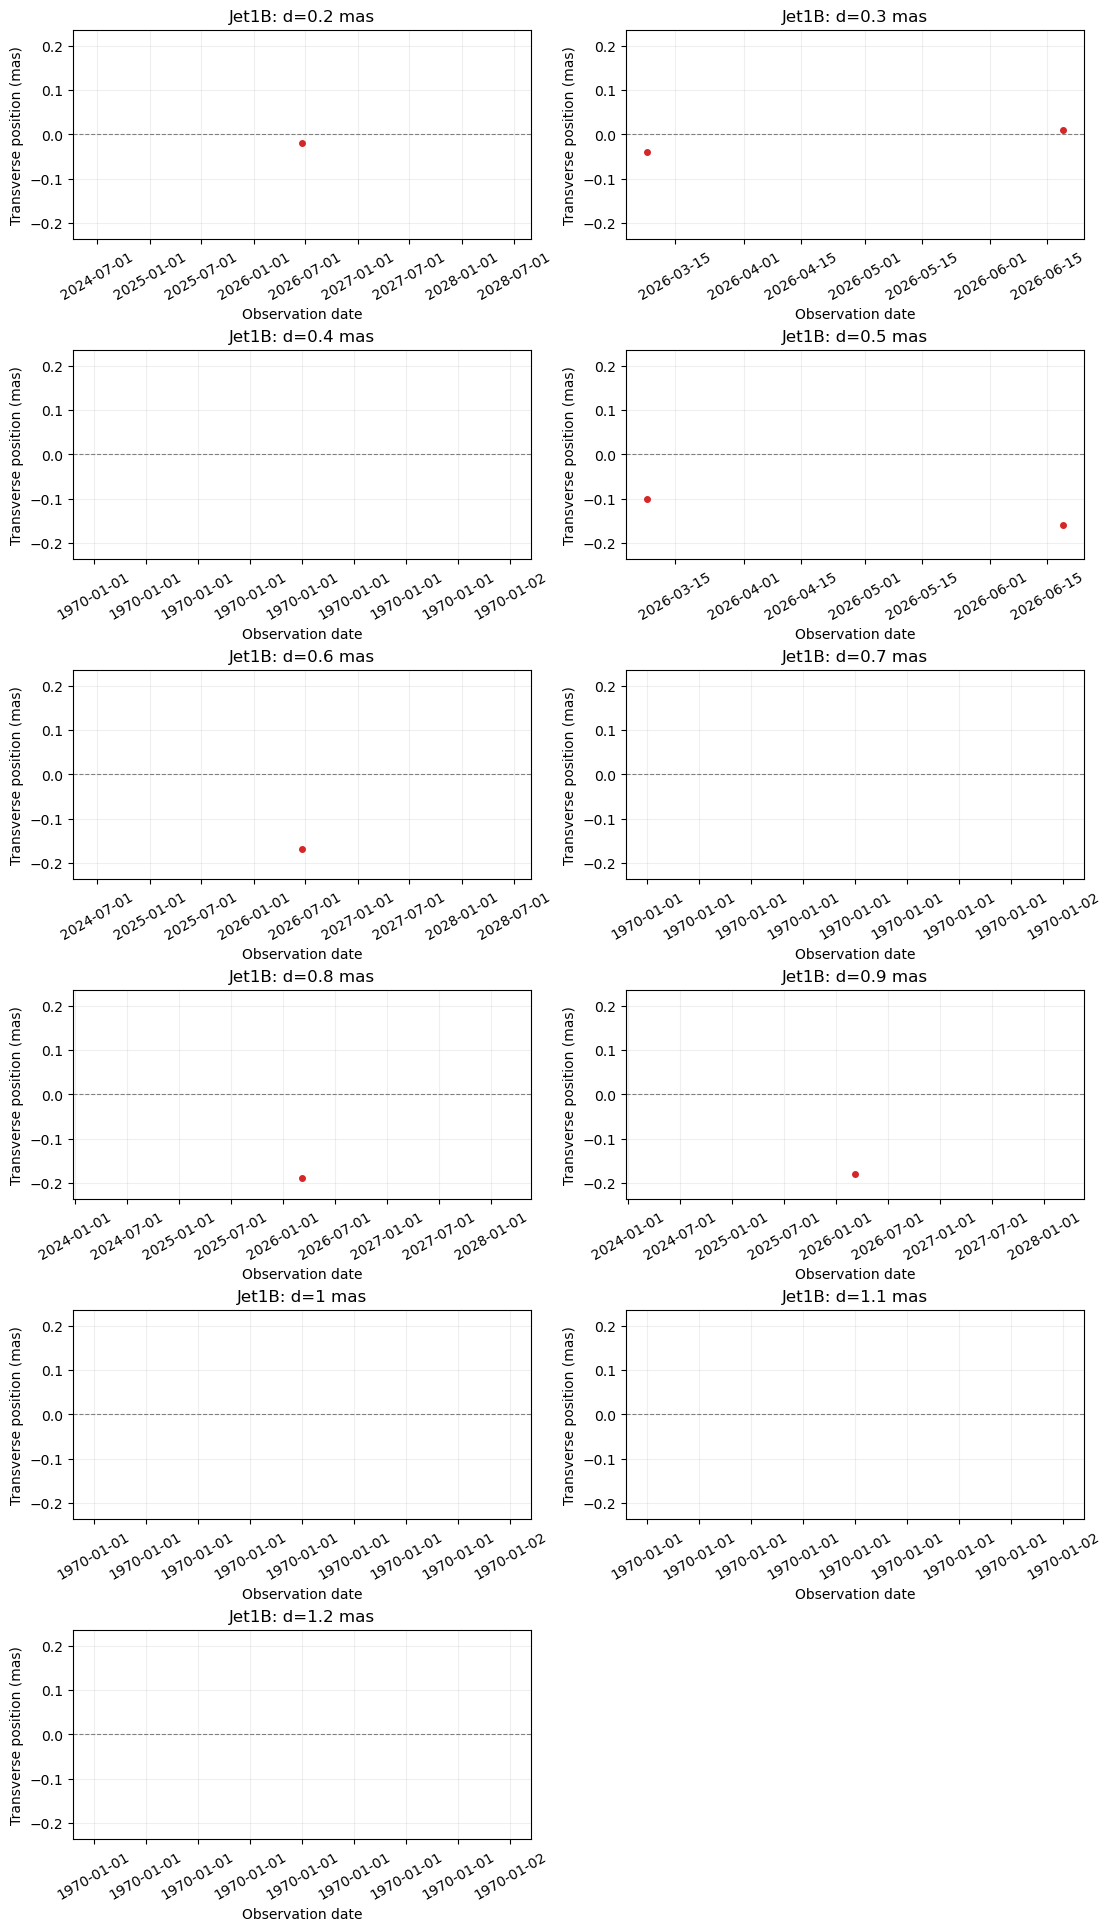

保存先：/Users/reiya/Desktop/imaging/results_fov3000/2026/Jet1AB_PA145_peak


In [26]:
# 各日について、Jet1B、Jet1Aの順に候補番号を入力
PEAK_SELECTION = select_peak_numbers()

# 横断位置を測定し、画像・CSV・時系列を保存
results, cores = run_analysis()

In [ ]:
if not results:
    raise ValueError("先にセル6を実行してresultsを作成してください")

adopted_count = 0

for row in results:
    if (
        row["component"] in ("Jet1A", "Jet1B")
        and row["requested"]
        and np.isfinite(row["transverse_mas"])
    ):
        if not row["accepted"]:
            adopted_count += 1

        row["accepted"] = True
        key = (row["epoch"], row["distance_mas"], row["component"])
        COMPONENT_REVIEW_OVERRIDES[key] = True

print(f"不採用から採用に変更：{adopted_count}点")

all_epochs = sorted(
    {row["epoch"] for row in results}
    | {row["epoch"] for row in cores}
)
times = [datetime.fromisoformat(epoch) for epoch in all_epochs]

positions = [
    abs(row["transverse_mas"])
    for row in results
    if row["component"] in ("Jet1A", "Jet1B")
    and row["accepted"]
    and np.isfinite(row["transverse_mas"])
]
ylimit = max(0.05, max(positions, default=0.04) * 1.25)

for component in ("Jet1A", "Jet1B"):
    fig, axes = panels()

    for j, distance in enumerate(DISTANCES_MAS):
        ax = axes.flat[j]
        by_epoch = {
            row["epoch"]: row
            for row in results
            if row["component"] == component
            and row["distance_mas"] == distance
            and row["accepted"]
        }

        values = [
            by_epoch[epoch]["transverse_mas"] if epoch in by_epoch else np.nan
            for epoch in all_epochs
        ]

        ax.plot(times, values, "o-", color=COLOURS[component], ms=4)
        ax.axhline(0, color="grey", ls="--", lw=0.8)
        ax.set(
            title=f"{component}: d={distance:g} mas",
            xlabel="Observation date",
            ylabel="Transverse position (mas)",
            ylim=(-ylimit, ylimit),
        )
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
        ax.tick_params(axis="x", labelrotation=30)
        ax.grid(alpha=0.2)

    for ax in list(axes.flat)[len(DISTANCES_MAS):]:
        ax.set_visible(False)

    path = OUT_DIR.expanduser() / "03_time_series" / f"{component}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)